# Frozen model evaluation

Conditional bounding-box localization, paired statistics, presence decisions, and residual-risk analysis from frozen model predictions.


In [1]:
from __future__ import annotations

import hashlib
import json
import re
import os
import sys
import time
import warnings
from pathlib import Path

import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image
from pydicom.pixels import (
    apply_modality_lut,
    apply_presentation_lut,
    apply_voi_lut,
)
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr, wilcoxon
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve,
)
from torch.utils.data import DataLoader, Dataset
from torchvision.models import resnet18

EXPECTED_PYTHON = Path(os.environ.get("MAMMO_PYTHON", "/home/azyqan/venvs/ml-torch/bin/python")).resolve()
assert Path(sys.executable).resolve() == EXPECTED_PYTHON
assert torch.cuda.is_available()
DEVICE = torch.device("cuda")


import os

_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    candidate for candidate in (_start, *_start.parents)
    if (candidate / "notebooks").is_dir()
    and (candidate / "artifacts").is_dir()
    and (candidate / "dataset").is_dir()
)
DATASET_ROOT = Path(os.environ.get("MAMMO_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
WORK_DATA_ROOT = Path(os.environ.get("MAMMO_WORK_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
DICOM_ROOT = DATASET_ROOT / "images_dicom"
if not DICOM_ROOT.is_dir() and (DATASET_ROOT / "images").is_dir():
    DICOM_ROOT = DATASET_ROOT / "images"
ANNOTATIONS = DATASET_ROOT / "annotations"
if not ANNOTATIONS.is_dir():
    ANNOTATIONS = DATASET_ROOT
RAW_DIR = WORK_DATA_ROOT / "Raw"
PROCESSED_DIR = WORK_DATA_ROOT / "Processed"
CONFIG_DIR = PROJECT_ROOT / "dataset" / "protocol"
MODEL_DIR = Path(os.environ.get("MAMMO_MODEL_ROOT", WORK_DATA_ROOT / "checkpoints")).expanduser().resolve()
COHORT_TABLES = PROJECT_ROOT / "dataset"
EDA_TABLES = PROJECT_ROOT / "artifacts" / "eda"
MODEL_TABLES = PROJECT_ROOT / "artifacts" / "models"
FIGURE_ROOT = PROJECT_ROOT / "figures"
FIGURE_INDEX = json.loads((FIGURE_ROOT / "index.json").read_text(encoding="utf-8"))
FIGURE_PATHS = {item["source"]: item["path"] for item in FIGURE_INDEX}

def resolve_figure(relative_path: str) -> Path:
    return PROJECT_ROOT / FIGURE_PATHS.get(relative_path, relative_path)

def protocol_table(name: str) -> Path:
    if name in ["bcrf_checkpoint_lineage.csv","bcrf_deployment_lineage.csv","bcrf_freeze_manifest.csv","frozen_evaluation_input_lineage.csv"]:
        return CONFIG_DIR / name
    return MODEL_TABLES / name

def resolve_dicom(relative_path: str) -> Path:
    name = Path(relative_path).name
    direct = DICOM_ROOT / name
    if direct.is_file():
        return direct
    candidates = list(DICOM_ROOT.rglob(name))
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one DICOM for {name}; found {len(candidates)}")
    return candidates[0]

def legacy_relative_path(path: Path) -> str:
    if path.name in ["bcrf_checkpoint_lineage.csv", "bcrf_deployment_lineage.csv", "bcrf_freeze_manifest.csv", "frozen_evaluation_input_lineage.csv"]:
        return "Tables/Models/" + path.name
    if path.is_relative_to(MODEL_DIR):
        return "Models/" + str(path.relative_to(MODEL_DIR))
    if path.is_relative_to(WORK_DATA_ROOT / "Raw"):
        return "Data/Raw/" + str(path.relative_to(WORK_DATA_ROOT / "Raw"))
    if path.is_relative_to(PROCESSED_DIR):
        return "Data/Processed/" + str(path.relative_to(PROCESSED_DIR))
    if path.is_relative_to(CONFIG_DIR):
        return "Config/" + str(path.relative_to(CONFIG_DIR))
    if path.is_relative_to(MODEL_TABLES):
        return "Tables/Models/" + str(path.relative_to(MODEL_TABLES))
    return str(path.relative_to(PROJECT_ROOT))

TABLE_DIR = MODEL_TABLES
DEVELOPMENT_FIGURE_DIR = FIGURE_ROOT
FIGURE_DIR = FIGURE_ROOT

SEEDS = (17, 29, 43)
IMAGE_SIZE = 512
MAX_PREDICTED_BOXES = 2
DPI = 350
FONT_PATH = font_manager.findfont(
    os.environ.get("MAMMO_FONT", "Times New Roman"),
    fallback_to_default=False,
)
mpl.rcParams.update(
    {
        "font.family": os.environ.get("MAMMO_FONT", "Times New Roman"),
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.titlesize": 20,
        "savefig.dpi": DPI,
    }
)
torch.set_float32_matmul_precision("high")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def canonical_sha256(payload: dict) -> str:
    raw = json.dumps(
        payload,
        sort_keys=True,
        separators=(",", ":"),
    ).encode()
    return hashlib.sha256(raw).hexdigest()


## Evaluation partitions

Validation is development data. The partition stored as `locked_test` is historically inspected internal retrospective data. CBIS-DDSM Calc-Test is a separate-source retrospective localization cohort. Frozen comparator thresholds retain incomplete historical selection provenance.


In [2]:
freeze_manifest = pd.read_csv(
    protocol_table("bcrf_freeze_manifest.csv")
)
checkpoint_lineage = pd.read_csv(
    protocol_table("bcrf_checkpoint_lineage.csv")
)
deployment_lineage = pd.read_csv(
    protocol_table("bcrf_deployment_lineage.csv")
)
selected_thresholds = pd.read_csv(
    TABLE_DIR / "baseline_selected_thresholds_source.csv"
)
bcrf_validation = pd.read_csv(
    TABLE_DIR / "bcrf_validation_predictions.csv"
)
manifest = pd.read_csv(
    RAW_DIR / "immutable_sample_manifest.csv"
)
cache_metadata = pd.read_csv(
    PROCESSED_DIR / "standard_dicom_1024_metadata.csv"
)
records = manifest.merge(
    cache_metadata[["image_id", "cache_index", "boxes_1024_json"]],
    on="image_id",
    validate="one_to_one",
)
image_cache = np.load(
    PROCESSED_DIR / "standard_dicom_1024_uint16.npy",
    mmap_mode="r",
)

for row in freeze_manifest.itertuples(index=False):
    candidate = {
        "immutable_sample_manifest.csv": (
            RAW_DIR / "immutable_sample_manifest.csv"
        ),
        "standard_dicom_1024_metadata.csv": (
            PROCESSED_DIR / "standard_dicom_1024_metadata.csv"
        ),
        "bcrf_validation_predictions.csv": (
            TABLE_DIR / "bcrf_validation_predictions.csv"
        ),
    }.get(row.artifact)
    if candidate is not None:
        assert sha256_file(candidate) == row.sha256

for row in deployment_lineage.itertuples(index=False):
    path = MODEL_DIR / row.artifact
    assert path.is_file()
    assert sha256_file(path) == row.sha256

assert len(checkpoint_lineage) == 15
assert checkpoint_lineage["checkpoint_sha256"].is_unique
assert bcrf_validation["split"].eq("validation").all()
assert bcrf_validation["model_spec_sha256"].nunique() == 1
assert records.groupby("study_id")["split"].nunique().max() == 1

cohort_inventory = (
    records.groupby("split", as_index=False)
    .agg(
        images=("image_id", "nunique"),
        studies=("study_id", "nunique"),
        positive_images=("label", "sum"),
    )
)
display(cohort_inventory.style.hide(axis="index"))
BCRF_FROZEN = True


split,images,studies,positive_images
calibration,183,101,40
locked_test,183,101,44
secondary_source_test,329,181,99
train,745,401,177
validation,182,101,42


In [3]:
PREDICTION_PROTOCOL = {
    "bbox_contract": "continuous_half_open_xyxy",
    "primary_endpoint": (
        "conditional pIoU on bbox-bearing positive images; "
        "image-to-study within seed; seed average"
    ),
    "system_secondary_endpoint": (
        "presence-aware system pIoU using frozen thresholds"
    ),
    "max_predicted_boxes": MAX_PREDICTED_BOXES,
    "baseline_status": "retrospective frozen implementations",
    "internal_status": "retrospective partition named locked_test",
}
PREDICTION_PROTOCOL_SHA256 = hashlib.sha256(
    json.dumps(
        PREDICTION_PROTOCOL,
        sort_keys=True,
    ).encode("utf-8")
).hexdigest()

def baseline_artifact_path(
    method: str,
    seed: int,
) -> Path:
    if method in {
        "grad_cam",
        "score_cam_top32",
        "Grad-CAM",
        "Score-CAM",
    }:
        return MODEL_DIR / f"cam_classifier_seed{seed}.pt"
    if method in {
        "unet_pseudomask",
        "U-Net pseudomask",
    }:
        return MODEL_DIR / f"unet_pseudomask_seed{seed}.pt"
    raise KeyError(method)

def artifact_lineage_for_row(
    method: str,
    seed: int,
) -> dict:
    if method == "DICOM-HUMap-BCRF":
        row = deployment_lineage[
            deployment_lineage["seed"].eq(seed)
        ].iloc[0]
        return {
            "artifact": row["artifact"],
            "artifact_sha256": row["sha256"],
            "source_checkpoint": row["source_checkpoint"],
            "source_checkpoint_sha256": (
                row["source_checkpoint_sha256"]
            ),
            "source_state_sha256": row["source_state_sha256"],
            "implementation_source_sha256": (
                row["implementation_source_sha256"]
            ),
            "model_spec_sha256": row["model_spec_sha256"],
        }
    path = baseline_artifact_path(method, seed)
    digest = sha256_file(path)
    return {
        "artifact": path.name,
        "artifact_sha256": digest,
        "source_checkpoint": path.name,
        "source_checkpoint_sha256": digest,
        "source_state_sha256": "",
        "implementation_source_sha256": "",
        "model_spec_sha256": "retrospective-frozen-baseline",
    }

def prediction_threshold_path(
    method: str,
) -> Path:
    if method == "DICOM-HUMap-BCRF":
        return TABLE_DIR / "bcrf_presence_thresholds.csv"
    return TABLE_DIR / "baseline_selected_thresholds_source.csv"

In [4]:
def frozen_input_sha256(path: Path) -> str:
    relative_path = legacy_relative_path(path)
    if "current_input_lineage" in globals():
        rows = current_input_lineage[
            current_input_lineage["path"].eq(relative_path)
        ]
        if len(rows) == 1:
            return str(rows.iloc[0]["sha256"])
    return sha256_file(path)


def attach_prediction_lineage(
    frame: pd.DataFrame,
    cache_path: Path,
) -> pd.DataFrame:
    frame = frame.copy()
    lineage_columns = [
        "artifact",
        "artifact_sha256",
        "source_checkpoint",
        "source_checkpoint_sha256",
        "source_state_sha256",
        "implementation_source_sha256",
        "model_spec_sha256",
        "threshold_source_sha256",
        "cache_sha256",
        "prediction_protocol_sha256",
    ]
    frame = frame.drop(
        columns=[
            column
            for column in lineage_columns
            if column in frame.columns
        ]
    )
    method_seed = frame[["method", "seed"]].drop_duplicates()
    lineage_rows = []
    for row in method_seed.itertuples(index=False):
        lineage = artifact_lineage_for_row(
            str(row.method),
            int(row.seed),
        )
        lineage.update(
            {
                "method": row.method,
                "seed": int(row.seed),
            }
        )
        lineage_rows.append(lineage)
    lineage = pd.DataFrame(lineage_rows)
    threshold_hashes = {
        method: sha256_file(prediction_threshold_path(str(method)))
        for method in frame["method"].unique()
    }
    lineage["threshold_source_sha256"] = lineage["method"].map(
        threshold_hashes
    )
    lineage["cache_sha256"] = frozen_input_sha256(cache_path)
    lineage["prediction_protocol_sha256"] = (
        PREDICTION_PROTOCOL_SHA256
    )
    frame["__row_order"] = np.arange(len(frame))
    frame = (
        frame.merge(
            lineage,
            on=["method", "seed"],
            how="left",
            validate="many_to_one",
        )
        .sort_values("__row_order")
        .drop(columns="__row_order")
        .reset_index(drop=True)
    )
    return frame


def assert_prediction_grid(
    frame: pd.DataFrame,
    methods: list[str],
    seeds: list[int],
    expected_image_ids: set[str],
) -> None:
    key_columns = ["method", "seed", "image_id"]
    if frame.duplicated(key_columns).any():
        raise ValueError("Duplicate prediction rows")
    observed_pairs = set(
        map(
            tuple,
            frame[["method", "seed"]]
            .drop_duplicates()
            .itertuples(index=False, name=None),
        )
    )
    expected_pairs = {
        (method, seed)
        for method in methods
        for seed in seeds
    }
    if observed_pairs != expected_pairs:
        raise ValueError(
            f"Incomplete method×seed grid: {observed_pairs}"
        )
    for pair, group in frame.groupby(["method", "seed"]):
        if set(group["image_id"]) != expected_image_ids:
            raise ValueError(f"Incomplete image coverage: {pair}")
    required_lineage = [
        "artifact_sha256",
        "source_checkpoint_sha256",
        "model_spec_sha256",
        "threshold_source_sha256",
        "cache_sha256",
        "prediction_protocol_sha256",
    ]
    if frame[required_lineage].isna().any().any():
        raise ValueError("Missing prediction lineage")
    if frame[required_lineage].eq("").any().any():
        raise ValueError("Blank required prediction lineage")


def assert_stored_prediction_lineage(
    stored: pd.DataFrame,
    current: pd.DataFrame,
) -> None:
    required = [
        "artifact_sha256",
        "source_checkpoint_sha256",
        "model_spec_sha256",
        "threshold_source_sha256",
        "cache_sha256",
        "prediction_protocol_sha256",
    ]
    missing = [column for column in required if column not in stored.columns]
    if missing:
        raise ValueError(f"Stored prediction lineage is missing: {missing}")
    for column in required:
        pd.testing.assert_series_equal(
            stored[column].astype(str).reset_index(drop=True),
            current[column].astype(str).reset_index(drop=True),
            check_names=False,
        )

In [5]:
from importlib import metadata as package_metadata

CREATE_EVALUATION_INPUT_LINEAGE = False
EVALUATION_INPUT_LINEAGE_PATH = (
    protocol_table("frozen_evaluation_input_lineage.csv")
)
external_root = RAW_DIR / "CBIS-DDSM_Calc-Test"
input_paths = {
    "split_protocol": CONFIG_DIR / "split_protocol.json",
    "project_charter": CONFIG_DIR / "project_charter.json",
    "evaluation_protocol": (
        CONFIG_DIR
        / "dicom_humap_evaluation_protocol.json"
    ),
    "internal_manifest": RAW_DIR / "immutable_sample_manifest.csv",
    "internal_metadata": (
        PROCESSED_DIR / "standard_dicom_1024_metadata.csv"
    ),
    "internal_cache": (
        PROCESSED_DIR / "standard_dicom_1024_uint16.npy"
    ),
    "baseline_thresholds": (
        TABLE_DIR / "baseline_selected_thresholds_source.csv"
    ),
    "bcrf_presence_thresholds": (
        TABLE_DIR / "bcrf_presence_thresholds.csv"
    ),
    "bcrf_validation_predictions": (
        TABLE_DIR / "bcrf_validation_predictions.csv"
    ),
    "bcrf_checkpoint_lineage": (
        protocol_table("bcrf_checkpoint_lineage.csv")
    ),
    "bcrf_deployment_lineage": (
        protocol_table("bcrf_deployment_lineage.csv")
    ),
    "external_series_manifest": (
        external_root / "immutable_external_series_manifest.csv"
    ),
    "external_annotations": (
        external_root / "calc_case_description_test_set.csv"
    ),
    "external_metadata": (
        PROCESSED_DIR
        / "cbis_ddsm_calc_test_1024_metadata.csv"
    ),
    "external_cache": (
        PROCESSED_DIR
        / "cbis_ddsm_calc_test_1024_uint16.npy"
    ),
}
for seed in SEEDS:
    input_paths[f"bcrf_deployment_seed{seed}"] = (
        MODEL_DIR
        / deployment_lineage.loc[
            deployment_lineage["seed"].eq(seed),
            "artifact",
        ].iloc[0]
    )
    input_paths[f"bcrf_checkpoint_seed{seed}"] = (
        MODEL_DIR
        / deployment_lineage.loc[
            deployment_lineage["seed"].eq(seed),
            "source_checkpoint",
        ].iloc[0]
    )
    input_paths[f"cam_checkpoint_seed{seed}"] = (
        MODEL_DIR / f"cam_classifier_seed{seed}.pt"
    )
    input_paths[f"unet_checkpoint_seed{seed}"] = (
        MODEL_DIR / f"unet_pseudomask_seed{seed}.pt"
    )

In [ ]:
for name, path in input_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name}: {path}")
current_input_lineage = pd.DataFrame(
    [
        {
            "artifact_role": name,
            "path": legacy_relative_path(path),
            "sha256": sha256_file(path),
            "bytes": path.stat().st_size,
        }
        for name, path in input_paths.items()
    ]
).sort_values("artifact_role", ignore_index=True)

if CREATE_EVALUATION_INPUT_LINEAGE:
    current_input_lineage.to_csv(
        EVALUATION_INPUT_LINEAGE_PATH,
        index=False,
    )
if not EVALUATION_INPUT_LINEAGE_PATH.is_file():
    raise FileNotFoundError(EVALUATION_INPUT_LINEAGE_PATH)
frozen_input_lineage = pd.read_csv(
    EVALUATION_INPUT_LINEAGE_PATH
).sort_values("artifact_role", ignore_index=True)
pd.testing.assert_frame_equal(
    current_input_lineage,
    frozen_input_lineage,
    check_dtype=False,
)


## Frozen comparator inference

Grad-CAM, Score-CAM and U-Net checkpoints are never retrained. Their frozen calibration thresholds and the same half-open bbox evaluator are used on identical images.

In [7]:
def normalize_map(array: np.ndarray) -> np.ndarray:
    array = np.asarray(array, dtype=np.float32)
    minimum = float(array.min())
    maximum = float(array.max())
    return (array - minimum) / max(maximum - minimum, 1e-6)

def scale_boxes(boxes_json: str) -> list[list[float]]:
    return (
        np.asarray(json.loads(boxes_json), dtype=np.float32)
        * (IMAGE_SIZE / 1024)
    ).tolist()

class FrozenImageDataset(Dataset):
    def __init__(
        self,
        frame: pd.DataFrame,
        cache: np.ndarray,
    ) -> None:
        self.frame = frame.reset_index(drop=True).copy()
        self.cache = cache

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> dict:
        row = self.frame.iloc[index]
        source = self.cache[int(row.cache_index)].astype(np.float32)
        source /= 65535.0
        image = cv2.resize(
            source,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_AREA,
        )
        valid = cv2.resize(
            (source > 0).astype(np.uint8),
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST,
        )
        return {
            "image": torch.from_numpy(image[None]).float(),
            "valid_mask": torch.from_numpy(valid[None]).float(),
            "image_id": str(row.image_id),
            "study_id": str(row.study_id),
            "label": int(row.label),
            "boxes_json": json.dumps(scale_boxes(row.boxes_1024_json)),
        }

def frozen_loader(
    frame: pd.DataFrame,
    cache: np.ndarray,
) -> DataLoader:
    return DataLoader(
        FrozenImageDataset(frame, cache),
        batch_size=1,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )

def continuous_iou(first: list[float], second: list[float]) -> float:
    x1 = max(first[0], second[0])
    y1 = max(first[1], second[1])
    x2 = min(first[2], second[2])
    y2 = min(first[3], second[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_first = max(0, first[2] - first[0]) * max(
        0, first[3] - first[1]
    )
    area_second = max(0, second[2] - second[0]) * max(
        0, second[3] - second[1]
    )
    return intersection / max(
        area_first + area_second - intersection,
        1e-8,
    )

def matched_localization(
    predicted: list[list[float]],
    target: list[list[float]],
) -> dict[str, float]:
    denominator = max(len(predicted), len(target), 1)
    if not predicted or not target:
        return {
            "matched_iou": 0.0,
            "penalized_iou": 0.0,
            "box_recall_0_1": 0.0,
            "false_positive_boxes": float(len(predicted)),
        }
    matrix = np.asarray(
        [
            [continuous_iou(first, second) for second in target]
            for first in predicted
        ]
    )
    rows, columns = linear_sum_assignment(1 - matrix)
    matched = matrix[rows, columns]
    return {
        "matched_iou": float(matched.mean()),
        "penalized_iou": float(matched.sum() / denominator),
        "box_recall_0_1": float((matched >= 0.10).sum() / len(target)),
        "false_positive_boxes": float(
            len(predicted) - (matched >= 0.10).sum()
        ),
    }

def boxes_from_heatmap(
    heatmap: np.ndarray,
    threshold: float,
) -> list[list[float]]:
    heatmap = normalize_map(heatmap)
    binary = (heatmap >= threshold).astype(np.uint8)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8,
    )
    candidates = []
    for label in range(1, count):
        x, y, width, height, area = stats[label]
        if area < 1:
            continue
        score = float(heatmap[labels == label].max())
        candidates.append(
            (score, [float(x), float(y), float(x + width), float(y + height)])
        )
    candidates.sort(key=lambda item: item[0], reverse=True)
    return [box for _, box in candidates[:MAX_PREDICTED_BOXES]]


In [8]:
def grayscale_resnet18() -> nn.Module:
    backbone = resnet18(weights=None)
    backbone.conv1 = nn.Conv2d(
        1,
        64,
        kernel_size=7,
        stride=2,
        padding=3,
        bias=False,
    )
    return backbone

class CAMClassifier(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        backbone = grayscale_resnet18()
        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4
        self.classifier = nn.Linear(512, 1)

    def features(self, image: torch.Tensor) -> torch.Tensor:
        value = self.stem(image)
        value = self.layer1(value)
        value = self.layer2(value)
        value = self.layer3(value)
        return self.layer4(value)

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        feature = self.features(image)
        return self.classifier(feature.mean((-2, -1)))[:, 0]

class DecoderBlock(nn.Module):
    def __init__(self, input_channels: int, output_channels: int):
        super().__init__()
        def block(in_channels: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    output_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False,
                ),
                nn.GroupNorm(8, output_channels),
                nn.ReLU(inplace=True),
            )
        self.block = nn.Sequential(
            block(input_channels),
            block(output_channels),
        )

    def forward(self, value: torch.Tensor) -> torch.Tensor:
        return self.block(value)

class UNetPseudomask(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        backbone = grayscale_resnet18()
        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4
        self.decoder4 = DecoderBlock(768, 256)
        self.decoder3 = DecoderBlock(384, 128)
        self.decoder2 = DecoderBlock(192, 64)
        self.head = nn.Sequential(
            nn.Sequential(
                nn.Conv2d(64, 32, 3, padding=1, bias=False),
                nn.GroupNorm(8, 32),
                nn.ReLU(inplace=True),
            ),
            nn.Conv2d(32, 1, 1),
        )

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        stem = self.stem(image)
        layer1 = self.layer1(stem)
        layer2 = self.layer2(layer1)
        layer3 = self.layer3(layer2)
        layer4 = self.layer4(layer3)
        value = self.decoder4(
            torch.cat(
                [F.interpolate(layer4, size=layer3.shape[-2:]), layer3],
                dim=1,
            )
        )
        value = self.decoder3(
            torch.cat(
                [F.interpolate(value, size=layer2.shape[-2:]), layer2],
                dim=1,
            )
        )
        value = self.decoder2(
            torch.cat(
                [F.interpolate(value, size=layer1.shape[-2:]), layer1],
                dim=1,
            )
        )
        logits = self.head(value)
        return torch.sigmoid(
            F.interpolate(
                logits,
                size=image.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )
        )


In [9]:
def load_baseline_model(method: str, seed: int) -> nn.Module:
    if method in {"grad_cam", "score_cam_top32"}:
        path = MODEL_DIR / f"cam_classifier_seed{seed}.pt"
        model = CAMClassifier()
    else:
        path = MODEL_DIR / f"unet_pseudomask_seed{seed}.pt"
        model = UNetPseudomask()
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )
    model.load_state_dict(checkpoint["model_state"], strict=True)
    model = model.to(DEVICE).eval()
    return model

def grad_cam_map(
    model: CAMClassifier,
    image: torch.Tensor,
) -> tuple[np.ndarray, float]:
    image = image.detach().requires_grad_(True)
    feature = model.features(image)
    logit = model.classifier(feature.mean((-2, -1)))[:, 0]
    gradient = torch.autograd.grad(logit.sum(), feature)[0]
    weights = gradient.mean((-2, -1), keepdim=True)
    heatmap = F.relu((weights * feature).sum(1, keepdim=True))
    heatmap = F.interpolate(
        heatmap,
        size=image.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )
    return (
        normalize_map(heatmap[0, 0].detach().cpu().numpy()),
        float(torch.sigmoid(logit[0]).detach()),
    )

@torch.no_grad()
def score_cam_map(
    model: CAMClassifier,
    image: torch.Tensor,
    top_k: int = 32,
) -> tuple[np.ndarray, float]:
    feature = F.relu(model.features(image))
    original_logit = model.classifier(feature.mean((-2, -1)))[:, 0]
    activation = F.interpolate(
        feature,
        size=image.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )[0]
    flat = activation.flatten(1)
    minimum = flat.min(1, keepdim=True).values
    maximum = flat.max(1, keepdim=True).values
    normalized = ((flat - minimum) / (maximum - minimum).clamp_min(1e-6))
    normalized = normalized.reshape_as(activation)
    energy = normalized.mean((-2, -1))
    indices = energy.topk(min(top_k, len(energy))).indices
    masks = normalized[indices, None]
    masked_images = image.repeat(len(indices), 1, 1, 1) * masks
    scores = []
    for chunk in masked_images.split(8):
        scores.append(torch.sigmoid(model(chunk)))
    weights = torch.cat(scores)
    heatmap = F.relu(
        (weights[:, None, None] * activation[indices]).sum(0)
    )
    return (
        normalize_map(heatmap.cpu().numpy()),
        float(torch.sigmoid(original_logit[0])),
    )

@torch.no_grad()
def unet_map(
    model: UNetPseudomask,
    image: torch.Tensor,
) -> tuple[np.ndarray, float]:
    heatmap = model(image)[0, 0].float().cpu().numpy()
    return heatmap, float(heatmap.max())

def baseline_heatmap(
    method: str,
    model: nn.Module,
    image: torch.Tensor,
) -> tuple[np.ndarray, float]:
    if method == "grad_cam":
        return grad_cam_map(model, image)
    if method == "score_cam_top32":
        return score_cam_map(model, image)
    return unet_map(model, image)


In [10]:
BASELINE_METHODS = (
    "grad_cam",
    "score_cam_top32",
    "unet_pseudomask",
)

def infer_baseline(
    method: str,
    seed: int,
    frame: pd.DataFrame,
    cache: np.ndarray,
    split: str,
) -> pd.DataFrame:
    threshold_row = selected_thresholds[
        selected_thresholds["method"].eq(method)
        & selected_thresholds["seed"].eq(seed)
    ].iloc[0]
    heatmap_threshold = float(threshold_row.heatmap_threshold)
    presence_threshold = float(threshold_row.presence_threshold)
    model = load_baseline_model(method, seed)
    rows = []
    started = time.perf_counter()
    for batch in frozen_loader(frame, cache):
        image = batch["image"].to(
            DEVICE,
            non_blocking=True,
        )
        heatmap, probability = baseline_heatmap(
            method,
            model,
            image,
        )
        conditional_boxes = boxes_from_heatmap(
            heatmap,
            heatmap_threshold,
        )
        system_boxes = (
            conditional_boxes
            if probability >= presence_threshold
            else []
        )
        target = json.loads(batch["boxes_json"][0])
        conditional_metrics = matched_localization(
            conditional_boxes,
            target,
        )
        system_metrics = matched_localization(system_boxes, target)
        peak_y, peak_x = np.unravel_index(
            int(np.argmax(heatmap)),
            heatmap.shape,
        )
        point_hit = int(
            any(
                x1 <= peak_x < x2 and y1 <= peak_y < y2
                for x1, y1, x2, y2 in target
            )
        )
        rows.append(
            {
                "split": split,
                "method": method,
                "seed": seed,
                "image_id": batch["image_id"][0],
                "study_id": batch["study_id"][0],
                "label": int(batch["label"][0]),
                "probability": probability,
                "presence_threshold": presence_threshold,
                "heatmap_threshold": heatmap_threshold,
                "target_count": len(target),
                "conditional_count": len(conditional_boxes),
                "predicted_count": len(system_boxes),
                "count_correct": int(len(system_boxes) == len(target)),
                "point_hit": point_hit,
                "conditional_boxes_json": json.dumps(conditional_boxes),
                "system_boxes_json": json.dumps(system_boxes),
                "target_boxes_json": json.dumps(target),
                **conditional_metrics,
                **{
                    f"system_{name}": value
                    for name, value in system_metrics.items()
                },
            }
        )
    elapsed = time.perf_counter() - started
    result = pd.DataFrame(rows)
    result["seconds_per_image"] = elapsed / max(len(result), 1)
    del model
    torch.cuda.empty_cache()
    return result


In [11]:
RUN_FROZEN_BASELINE_VALIDATION = False
REFRESH_VALIDATION_PREDICTION_LINEAGE = False
VALIDATION_BASELINE_PATH = (
    TABLE_DIR / "baseline_validation_predictions_frozen.csv"
)
validation_frame = records[records["split"].eq("validation")].copy()

if RUN_FROZEN_BASELINE_VALIDATION:
    validation_baseline_frames = []
    for method in BASELINE_METHODS:
        for seed in SEEDS:
            frame = infer_baseline(
                method,
                seed,
                validation_frame,
                image_cache,
                "validation",
            )
            validation_baseline_frames.append(frame)
            print(method, seed, len(frame))
    baseline_validation = pd.concat(
        validation_baseline_frames,
        ignore_index=True,
    )
else:
    if not VALIDATION_BASELINE_PATH.is_file():
        raise FileNotFoundError(
            f"Frozen validation inference is missing: {VALIDATION_BASELINE_PATH}"
        )
    baseline_validation = pd.read_csv(VALIDATION_BASELINE_PATH)

stored_baseline_validation = baseline_validation.copy()
expected_ids = set(validation_frame["image_id"])
baseline_validation = attach_prediction_lineage(
    baseline_validation,
    PROCESSED_DIR / "standard_dicom_1024_uint16.npy",
)
assert_prediction_grid(
    baseline_validation,
    list(BASELINE_METHODS),
    list(SEEDS),
    expected_ids,
)
if (
    RUN_FROZEN_BASELINE_VALIDATION
    or REFRESH_VALIDATION_PREDICTION_LINEAGE
):
    baseline_validation.to_csv(
        VALIDATION_BASELINE_PATH,
        index=False,
    )
else:
    assert_stored_prediction_lineage(
        stored_baseline_validation,
        baseline_validation,
    )
coverage = (
    baseline_validation.groupby(["method", "seed"], as_index=False)
    .agg(
        images=("image_id", "nunique"),
        studies=("study_id", "nunique"),
    )
)

validation_seed_summary = (
    baseline_validation[baseline_validation["label"].eq(1)]
    .groupby(["method", "seed"], as_index=False)
    .agg(
        penalized_iou=("penalized_iou", "mean"),
        matched_iou=("matched_iou", "mean"),
        point_hit=("point_hit", "mean"),
    )
)
display(
    validation_seed_summary.style.hide(axis="index").format(precision=4)
)


method,seed,penalized_iou,matched_iou,point_hit
grad_cam,17,0.0002,0.0002,0.0000
grad_cam,29,0.0000,0.0000,0.0000
grad_cam,43,0.0000,0.0000,0.0000
score_cam_top32,17,0.0168,0.0195,0.0000
score_cam_top32,29,0.0097,0.0168,0.0000
score_cam_top32,43,0.0168,0.0195,0.0000
unet_pseudomask,17,0.1939,0.2172,0.5952
unet_pseudomask,29,0.2010,0.2377,0.6667
unet_pseudomask,43,0.2269,0.2789,0.6190


## Frozen retrospective evaluation

Presence thresholds for DICOM-HUMap-BCRF are read from the frozen calibration artifact. The historically inspected internal partition and CBIS-DDSM external partition are evaluated under immutable input, model, decoder, and protocol hashes without outcome-driven retuning.

In [12]:
def load_bcrf(seed: int) -> torch.jit.ScriptModule:
    row = deployment_lineage[deployment_lineage["seed"].eq(seed)].iloc[0]
    model = torch.jit.load(
        MODEL_DIR / row.artifact,
        map_location=DEVICE,
    )
    return model.eval()

def decode_bcrf(
    output: dict[str, torch.Tensor],
) -> list[list[float]]:
    requested = min(
        int(output["count_logits"][0].argmax().item()) + 1,
        MAX_PREDICTED_BOXES,
    )
    center = output["center_probability"][0, 0]
    local_maximum = center.eq(
        F.max_pool2d(
            center[None, None],
            kernel_size=3,
            stride=1,
            padding=1,
        )[0, 0]
    )
    scores = center.masked_fill(~local_maximum, -1)
    _, indices = scores.flatten().topk(requested)
    boxes = []
    center_size = center.shape[-1]
    stride = IMAGE_SIZE / center_size
    for flat_index in indices:
        grid_y = int(flat_index // center_size)
        grid_x = int(flat_index % center_size)
        offset = output["offset"][0, :, grid_y, grid_x]
        log_size = output["log_size"][
            0, :, grid_y, grid_x
        ].clamp(-np.log(IMAGE_SIZE), 0)
        width, height = torch.exp(log_size) * IMAGE_SIZE
        center_x = (grid_x + float(offset[0])) * stride
        center_y = (grid_y + float(offset[1])) * stride
        width = float(width.clamp(1, IMAGE_SIZE))
        height = float(height.clamp(1, IMAGE_SIZE))
        boxes.append(
            [
                max(0.0, center_x - width / 2),
                max(0.0, center_y - height / 2),
                min(float(IMAGE_SIZE), center_x + width / 2),
                min(float(IMAGE_SIZE), center_y + height / 2),
            ]
        )
    return boxes

@torch.no_grad()
def infer_bcrf(
    seed: int,
    frame: pd.DataFrame,
    cache: np.ndarray,
    split: str,
    presence_threshold: float = 0.5,
) -> pd.DataFrame:
    model = load_bcrf(seed)
    rows = []
    started = time.perf_counter()
    for batch in frozen_loader(frame, cache):
        image = batch["image"].to(DEVICE, non_blocking=True)
        valid = batch["valid_mask"].to(DEVICE, non_blocking=True)
        output = model(image, valid)
        probability = float(torch.sigmoid(output["presence_logits"])[0])
        conditional_boxes = decode_bcrf(output)
        system_boxes = (
            conditional_boxes
            if probability >= presence_threshold
            else []
        )
        target = json.loads(batch["boxes_json"][0])
        conditional_metrics = matched_localization(
            conditional_boxes,
            target,
        )
        system_metrics = matched_localization(system_boxes, target)
        heatmap = output["heatmap"][0, 0].float().cpu().numpy()
        uncertainty = output["uncertainty"][0, 0].float().cpu().numpy()
        peak_y, peak_x = np.unravel_index(
            int(np.argmax(heatmap)),
            heatmap.shape,
        )
        rows.append(
            {
                "split": split,
                "method": "DICOM-HUMap-BCRF",
                "seed": seed,
                "image_id": batch["image_id"][0],
                "study_id": batch["study_id"][0],
                "label": int(batch["label"][0]),
                "probability": probability,
                "presence_threshold": presence_threshold,
                "target_count": len(target),
                "conditional_count": len(conditional_boxes),
                "predicted_count": len(system_boxes),
                "count_correct": int(len(system_boxes) == len(target)),
                "point_hit": int(
                    any(
                        x1 <= peak_x < x2 and y1 <= peak_y < y2
                        for x1, y1, x2, y2 in target
                    )
                ),
                "mean_uncertainty": float(uncertainty[valid[0, 0].cpu().numpy() > 0].mean()),
                "conditional_boxes_json": json.dumps(conditional_boxes),
                "system_boxes_json": json.dumps(system_boxes),
                "target_boxes_json": json.dumps(target),
                **conditional_metrics,
                **{
                    f"system_{name}": value
                    for name, value in system_metrics.items()
                },
            }
        )
    result = pd.DataFrame(rows)
    result["seconds_per_image"] = (
        time.perf_counter() - started
    ) / max(len(result), 1)
    del model
    torch.cuda.empty_cache()
    return result


In [13]:
RUN_BCRF_CALIBRATION = False
RUN_INTERNAL_RETROSPECTIVE_INFERENCE = False
REFRESH_INTERNAL_PREDICTION_LINEAGE = False
CALIBRATION_PATH = TABLE_DIR / "bcrf_calibration_predictions.csv"
PRESENCE_THRESHOLD_PATH = TABLE_DIR / "bcrf_presence_thresholds.csv"
LOCKED_PATH = TABLE_DIR / "locked_test_model_predictions_frozen.csv"

calibration_frame = records[records["split"].eq("calibration")].copy()
if RUN_BCRF_CALIBRATION:
    calibration_predictions = pd.concat(
        [
            infer_bcrf(
                seed,
                calibration_frame,
                image_cache,
                "calibration",
            )
            for seed in SEEDS
        ],
        ignore_index=True,
    )
    calibration_predictions.to_csv(CALIBRATION_PATH, index=False)
else:
    if not CALIBRATION_PATH.is_file():
        raise FileNotFoundError(CALIBRATION_PATH)
    calibration_predictions = pd.read_csv(CALIBRATION_PATH)

if RUN_BCRF_CALIBRATION:
    threshold_rows = []
    for seed, frame in calibration_predictions.groupby("seed"):
        false_positive_rate, true_positive_rate, thresholds = roc_curve(
            frame["label"],
            frame["probability"],
        )
        youden = true_positive_rate - false_positive_rate
        best = np.flatnonzero(youden == youden.max())
        index = best[np.argmax(thresholds[best])]
        threshold_rows.append(
            {
                "seed": seed,
                "presence_threshold": float(thresholds[index]),
                "youden_j": float(youden[index]),
                "calibration_images": len(frame),
            }
        )
    bcrf_presence_thresholds = pd.DataFrame(threshold_rows)
    bcrf_presence_thresholds.to_csv(
        PRESENCE_THRESHOLD_PATH,
        index=False,
    )
else:
    if not PRESENCE_THRESHOLD_PATH.is_file():
        raise FileNotFoundError(PRESENCE_THRESHOLD_PATH)
    bcrf_presence_thresholds = pd.read_csv(
        PRESENCE_THRESHOLD_PATH
    )
if set(bcrf_presence_thresholds["seed"]) != set(SEEDS):
    raise ValueError("Incomplete BCRF presence thresholds")
locked_frame = records[records["split"].eq("locked_test")].copy()
if RUN_INTERNAL_RETROSPECTIVE_INFERENCE:
    if not LOCKED_PATH.is_file():
        raise FileNotFoundError(LOCKED_PATH)
    frozen_existing = pd.read_csv(LOCKED_PATH)
    locked_frames = [
        frozen_existing[
            ~frozen_existing["method"].eq("DICOM-HUMap-BCRF")
        ].copy()
    ]
    for seed in SEEDS:
        threshold = float(
            bcrf_presence_thresholds.loc[
                bcrf_presence_thresholds["seed"].eq(seed),
                "presence_threshold",
            ].iloc[0]
        )
        locked_frames.append(
            infer_bcrf(
                seed,
                locked_frame,
                image_cache,
                "locked_test",
                threshold,
            )
        )
    locked_predictions = pd.concat(locked_frames, ignore_index=True)
    locked_predictions.to_csv(LOCKED_PATH, index=False)
else:
    if not LOCKED_PATH.is_file():
        raise FileNotFoundError(LOCKED_PATH)
    locked_predictions = pd.read_csv(LOCKED_PATH)

stored_locked_predictions = locked_predictions.copy()
expected_locked_ids = set(locked_frame["image_id"])
locked_predictions = attach_prediction_lineage(
    locked_predictions,
    PROCESSED_DIR / "standard_dicom_1024_uint16.npy",
)
assert_prediction_grid(
    locked_predictions,
    ["DICOM-HUMap-BCRF", *list(BASELINE_METHODS)],
    list(SEEDS),
    expected_locked_ids,
)
if (
    RUN_INTERNAL_RETROSPECTIVE_INFERENCE
    or REFRESH_INTERNAL_PREDICTION_LINEAGE
):
    locked_predictions.to_csv(LOCKED_PATH, index=False)
else:
    assert_stored_prediction_lineage(
        stored_locked_predictions,
        locked_predictions,
    )
display(
    bcrf_presence_thresholds.style.hide(axis="index").format(precision=4)
)


seed,presence_threshold,youden_j,calibration_images
17,0.4246,0.1108,183
29,0.4239,0.0755,183
43,0.5055,0.0998,183


In [14]:
EXTERNAL_ROOT = RAW_DIR / "CBIS-DDSM_Calc-Test"
EXTERNAL_CACHE_PATH = (
    PROCESSED_DIR / "cbis_ddsm_calc_test_1024_uint16.npy"
)
EXTERNAL_METADATA_PATH = (
    PROCESSED_DIR / "cbis_ddsm_calc_test_1024_metadata.csv"
)

def stored_padding_mask(
    stored: np.ndarray,
    dataset: pydicom.Dataset,
) -> np.ndarray:
    if not hasattr(dataset, "PixelPaddingValue"):
        return np.zeros(stored.shape, dtype=bool)
    first = float(dataset.PixelPaddingValue)
    second = float(
        getattr(dataset, "PixelPaddingRangeLimit", first)
    )
    lower, upper = sorted((first, second))
    return (stored >= lower) & (stored <= upper)

def normalize_valid_pixels(
    values: np.ndarray,
    valid: np.ndarray,
) -> np.ndarray:
    selected = values[valid & np.isfinite(values)]
    if selected.size == 0 or not selected.max() > selected.min():
        raise ValueError("Degenerate DICOM presentation range")
    image = np.zeros(values.shape, dtype=np.float32)
    image[valid] = np.clip(
        (values[valid] - selected.min())
        / (selected.max() - selected.min()),
        0,
        1,
    )
    return image

def standard_dicom_render(path: Path) -> tuple[np.ndarray, np.ndarray]:
    dataset = pydicom.dcmread(path)
    stored = dataset.pixel_array
    valid = ~stored_padding_mask(stored, dataset)
    modality = np.asarray(
        apply_modality_lut(stored, dataset),
        dtype=np.float64,
    )
    voi = np.asarray(
        apply_voi_lut(modality, dataset, index=0, prefer_lut=True),
        dtype=np.float64,
    )
    has_presentation = (
        hasattr(dataset, "PresentationLUTShape")
        or hasattr(dataset, "PresentationLUTSequence")
    )
    if has_presentation:
        presented = np.asarray(
            apply_presentation_lut(voi, dataset),
            dtype=np.float64,
        )
    elif str(
        getattr(dataset, "PhotometricInterpretation", "")
    ).upper() == "MONOCHROME1":
        selected = voi[valid & np.isfinite(voi)]
        presented = selected.min() + selected.max() - voi
    else:
        presented = voi
    return normalize_valid_pixels(presented, valid), valid

def resize_and_pad(
    image: np.ndarray,
    valid: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, dict]:
    height, width = image.shape
    scale = min(1024 / height, 1024 / width)
    resized_height = int(round(height * scale))
    resized_width = int(round(width * scale))
    top = (1024 - resized_height) // 2
    left = (1024 - resized_width) // 2
    canvas = np.zeros((1024, 1024), dtype=np.float32)
    mask = np.zeros((1024, 1024), dtype=bool)
    canvas[top:top + resized_height, left:left + resized_width] = (
        cv2.resize(
            image,
            (resized_width, resized_height),
            interpolation=cv2.INTER_LINEAR,
        )
    )
    mask[top:top + resized_height, left:left + resized_width] = (
        cv2.resize(
            valid.astype(np.uint8),
            (resized_width, resized_height),
            interpolation=cv2.INTER_NEAREST,
        ).astype(bool)
    )
    transform = {"scale": scale, "top": top, "left": left}
    return canvas, mask, transform

def extract_series_uid(value: str) -> str:
    matches = re.findall(r"1(?:\.\d+)+", str(value))
    if not matches:
        raise ValueError(f"No SeriesInstanceUID in {value}")
    return matches[-1]

def local_series_files(
    row: pd.Series,
) -> list[Path]:
    path = (
        EXTERNAL_ROOT
        / "dicom"
        / str(row.PatientID)
        / str(row.get("SeriesInstanceUID", row.name))
    )
    files = sorted(path.glob("*.dcm"))
    if not files:
        raise FileNotFoundError(path)
    return files

def roi_bbox(
    files: list[Path],
    expected_shape: tuple[int, int],
) -> list[float]:
    candidates = []
    for path in files:
        dataset = pydicom.dcmread(path)
        pixels = dataset.pixel_array
        values, counts = np.unique(pixels, return_counts=True)
        background = values[np.argmax(counts)]
        foreground = pixels != background
        candidates.append(
            {
                "unique_values": len(values),
                "foreground_fraction": float(foreground.mean()),
                "pixels": int(pixels.size),
                "foreground": foreground,
            }
        )
    candidates = [
        item
        for item in candidates
        if 0.0 < item["foreground_fraction"] < 0.5
    ]
    if not candidates:
        raise ValueError("No valid ROI mask candidate")
    selected = min(
        candidates,
        key=lambda item: (
            item["unique_values"],
            item["foreground_fraction"],
            -item["pixels"],
        ),
    )
    foreground = selected["foreground"]
    if foreground.shape != expected_shape:
        relative_error = max(
            abs(foreground.shape[0] - expected_shape[0]) / expected_shape[0],
            abs(foreground.shape[1] - expected_shape[1]) / expected_shape[1],
        )
        if relative_error > 0.02:
            raise ValueError(
                f"ROI/full shape mismatch: {foreground.shape} != "
                f"{expected_shape}"
            )
        foreground = cv2.resize(
            foreground.astype(np.uint8),
            (expected_shape[1], expected_shape[0]),
            interpolation=cv2.INTER_NEAREST,
        ).astype(bool)
    yy, xx = np.where(foreground)
    if len(xx) == 0:
        raise ValueError("Empty ROI mask")
    return [
        float(xx.min()),
        float(yy.min()),
        float(xx.max() + 1),
        float(yy.max() + 1),
    ]


In [15]:
RUN_EXTERNAL_PREPARATION = False
RUN_EXTERNAL_RETROSPECTIVE_INFERENCE = False
REFRESH_EXTERNAL_PREDICTION_LINEAGE = False
EXTERNAL_PREDICTION_PATH = (
    TABLE_DIR / "cbis_ddsm_calc_test_model_predictions.csv"
)

if RUN_EXTERNAL_PREPARATION:
    series_manifest = pd.read_csv(
        EXTERNAL_ROOT / "immutable_external_series_manifest.csv"
    )
    annotations = pd.read_csv(
        EXTERNAL_ROOT / "calc_case_description_test_set.csv"
    )
    annotations["image_series_uid"] = annotations[
        "image file path"
    ].map(extract_series_uid)
    annotations["roi_series_uid"] = annotations[
        "ROI mask file path"
    ].map(extract_series_uid)
    series_index = series_manifest.set_index("SeriesInstanceUID")
    cache_rows = []
    metadata_rows = []
    for cache_index, (image_uid, group) in enumerate(
        annotations.groupby("image_series_uid", sort=True)
    ):
        full_row = series_index.loc[image_uid]
        full_path = local_series_files(full_row)[0]
        image, valid = standard_dicom_render(full_path)
        canvas, _, transform = resize_and_pad(image, valid)
        boxes = []
        for roi_uid in group["roi_series_uid"]:
            roi_row = series_index.loc[roi_uid]
            box = roi_bbox(local_series_files(roi_row), image.shape)
            boxes.append(
                [
                    box[0] * transform["scale"] + transform["left"],
                    box[1] * transform["scale"] + transform["top"],
                    box[2] * transform["scale"] + transform["left"],
                    box[3] * transform["scale"] + transform["top"],
                ]
            )
        cache_rows.append(
            np.round(canvas * 65535).astype(np.uint16)
        )
        first = group.iloc[0]
        metadata_rows.append(
            {
                "image_id": image_uid,
                "study_id": str(first["patient_id"]),
                "cache_index": cache_index,
                "label": 1,
                "boxes_1024_json": json.dumps(boxes),
                "pathology": "|".join(
                    sorted(group["pathology"].astype(str).unique())
                ),
                "source_series_uid": image_uid,
            }
        )
    external_cache_array = np.stack(cache_rows)
    external_metadata = pd.DataFrame(metadata_rows)
    np.save(EXTERNAL_CACHE_PATH, external_cache_array)
    external_metadata.to_csv(EXTERNAL_METADATA_PATH, index=False)
else:
    if not EXTERNAL_CACHE_PATH.is_file():
        raise FileNotFoundError(EXTERNAL_CACHE_PATH)
    if not EXTERNAL_METADATA_PATH.is_file():
        raise FileNotFoundError(EXTERNAL_METADATA_PATH)
    external_metadata = pd.read_csv(EXTERNAL_METADATA_PATH)

external_cache = np.load(EXTERNAL_CACHE_PATH, mmap_mode="r")
assert len(external_metadata) == len(external_cache)
assert external_metadata["image_id"].is_unique
assert external_metadata["boxes_1024_json"].map(
    lambda value: len(json.loads(value))
).sum() == 326

if RUN_EXTERNAL_RETROSPECTIVE_INFERENCE:
    if not EXTERNAL_PREDICTION_PATH.is_file():
        raise FileNotFoundError(EXTERNAL_PREDICTION_PATH)
    frozen_existing = pd.read_csv(EXTERNAL_PREDICTION_PATH)
    external_frames = [
        frozen_existing[
            ~frozen_existing["method"].eq("DICOM-HUMap-BCRF")
        ].copy()
    ]
    for seed in SEEDS:
        threshold = float(
            bcrf_presence_thresholds.loc[
                bcrf_presence_thresholds["seed"].eq(seed),
                "presence_threshold",
            ].iloc[0]
        )
        external_frames.append(
            infer_bcrf(
                seed,
                external_metadata,
                external_cache,
                "cbis_ddsm_calc_test",
                threshold,
            )
        )
    external_predictions = pd.concat(
        external_frames,
        ignore_index=True,
    )
    external_predictions.to_csv(
        EXTERNAL_PREDICTION_PATH,
        index=False,
    )
else:
    if not EXTERNAL_PREDICTION_PATH.is_file():
        raise FileNotFoundError(EXTERNAL_PREDICTION_PATH)
    external_predictions = pd.read_csv(EXTERNAL_PREDICTION_PATH)

stored_external_predictions = external_predictions.copy()
expected_external_ids = set(external_metadata["image_id"])
external_predictions = attach_prediction_lineage(
    external_predictions,
    EXTERNAL_CACHE_PATH,
)
assert_prediction_grid(
    external_predictions,
    ["DICOM-HUMap-BCRF", *list(BASELINE_METHODS)],
    list(SEEDS),
    expected_external_ids,
)
if (
    RUN_EXTERNAL_RETROSPECTIVE_INFERENCE
    or REFRESH_EXTERNAL_PREDICTION_LINEAGE
):
    external_predictions.to_csv(
        EXTERNAL_PREDICTION_PATH,
        index=False,
    )
else:
    assert_stored_prediction_lineage(
        stored_external_predictions,
        external_predictions,
    )
display(
    pd.DataFrame(
        [
            {
                "images": len(external_metadata),
                "patients": external_metadata["study_id"].nunique(),
                "boxes": 326,
                "cache_sha256": sha256_file(EXTERNAL_CACHE_PATH),
            }
        ]
    ).style.hide(axis="index")
)


images,patients,boxes,cache_sha256
284,151,326,7ad8d859135344febeb1dca30110d06b531e0b9a32460676f0f5068e93db0373


In [16]:
METHOD_ORDER = (
    "DICOM-HUMap-BCRF",
    "U-Net pseudomask",
    "Grad-CAM",
    "Score-CAM",
)
METHOD_LABELS = {
    "unet_pseudomask": "U-Net pseudomask",
    "grad_cam": "Grad-CAM",
    "score_cam_top32": "Score-CAM",
}

bcrf_validation_full = bcrf_validation[
    bcrf_validation["variant"].eq("full_bcrf")
].copy()
bcrf_validation_full["method"] = "DICOM-HUMap-BCRF"
bcrf_validation_full = bcrf_validation_full.rename(
    columns={
        "presence_probability": "probability",
        "peak_in_box": "point_hit",
    }
)
bcrf_validation_full = attach_prediction_lineage(
    bcrf_validation_full,
    PROCESSED_DIR / "standard_dicom_1024_uint16.npy",
)
assert_prediction_grid(
    bcrf_validation_full,
    ["DICOM-HUMap-BCRF"],
    list(SEEDS),
    set(records.loc[records["split"].eq("validation"), "image_id"]),
)
for frame in (baseline_validation, locked_predictions, external_predictions):
    frame["method"] = frame["method"].replace(METHOD_LABELS)

validation_predictions = pd.concat(
    [bcrf_validation_full, baseline_validation],
    ignore_index=True,
    sort=False,
)
assert_prediction_grid(
    validation_predictions,
    list(METHOD_ORDER),
    list(SEEDS),
    set(records.loc[records["split"].eq("validation"), "image_id"]),
)
VALIDATION_PREDICTION_PATH = (
    TABLE_DIR / "validation_model_predictions_frozen.csv"
)
validation_predictions.to_csv(
    VALIDATION_PREDICTION_PATH,
    index=False,
)

all_predictions = pd.concat(
    [
        bcrf_validation_full,
        baseline_validation,
        locked_predictions,
        external_predictions,
    ],
    ignore_index=True,
    sort=False,
)
positive_predictions = all_predictions[all_predictions["label"].eq(1)]
study_seed = (
    positive_predictions.groupby(
        ["split", "method", "seed", "study_id"],
        as_index=False,
    )
    .agg(
        penalized_iou=("penalized_iou", "mean"),
        matched_iou=("matched_iou", "mean"),
        point_hit=("point_hit", "mean"),
        box_recall_0_1=("box_recall_0_1", "mean"),
    )
)
study_average = (
    study_seed.groupby(
        ["split", "method", "study_id"],
        as_index=False,
    )
    .mean(numeric_only=True)
)
model_summary = (
    study_average.groupby(["split", "method"], as_index=False)
    .agg(
        studies=("study_id", "nunique"),
        penalized_iou_mean=("penalized_iou", "mean"),
        penalized_iou_sd=("penalized_iou", "std"),
        matched_iou_mean=("matched_iou", "mean"),
        point_hit_mean=("point_hit", "mean"),
        box_recall_mean=("box_recall_0_1", "mean"),
    )
)
model_summary.to_csv(
    TABLE_DIR / "frozen_model_comparison_by_split.csv",
    index=False,
)

rng = np.random.default_rng(20260731)
contrast_rows = []
for split, frame in study_average.groupby("split"):
    wide = frame.pivot(
        index="study_id",
        columns="method",
        values="penalized_iou",
    )
    split_rows = []
    for comparator in METHOD_ORDER[1:]:
        paired = wide[["DICOM-HUMap-BCRF", comparator]].dropna()
        delta = (
            paired["DICOM-HUMap-BCRF"] - paired[comparator]
        ).to_numpy()
        bootstrap = rng.choice(
            delta,
            size=(10_000, len(delta)),
            replace=True,
        ).mean(axis=1)
        _, p_value = wilcoxon(
            delta,
            alternative="greater",
            zero_method="pratt",
        )
        split_rows.append(
            {
                "split": split,
                "comparator": comparator,
                "studies": len(delta),
                "mean_delta": delta.mean(),
                "ci95_low": np.quantile(bootstrap, 0.025),
                "ci95_high": np.quantile(bootstrap, 0.975),
                "wilcoxon_p": p_value,
            }
        )
    order = np.argsort([row["wilcoxon_p"] for row in split_rows])
    running = 0.0
    for rank, index in enumerate(order):
        candidate = min(
            1.0,
            (len(order) - rank)
            * split_rows[index]["wilcoxon_p"],
        )
        running = max(running, candidate)
        split_rows[index]["holm_p"] = running
    contrast_rows.extend(split_rows)

model_contrasts = pd.DataFrame(contrast_rows)
model_contrasts.to_csv(
    TABLE_DIR / "frozen_model_paired_contrasts.csv",
    index=False,
)
display(
    model_summary.style.hide(axis="index")
    .format(precision=4)
    .highlight_max(
        subset=[
            "penalized_iou_mean",
            "matched_iou_mean",
            "point_hit_mean",
            "box_recall_mean",
        ],
        props="font-weight: bold",
    )
)
display(
    model_contrasts.style.hide(axis="index").format(precision=4)
)


split,method,studies,penalized_iou_mean,penalized_iou_sd,matched_iou_mean,point_hit_mean,box_recall_mean
cbis_ddsm_calc_test,DICOM-HUMap-BCRF,151,0.0638,0.0854,0.0678,0.1628,0.1867
cbis_ddsm_calc_test,Grad-CAM,151,0.0000,0.0003,0.0001,0.0000,0.0000
cbis_ddsm_calc_test,Score-CAM,151,0.0086,0.0132,0.0106,0.0000,0.0033
cbis_ddsm_calc_test,U-Net pseudomask,151,0.0591,0.0881,0.0752,0.1370,0.2050
locked_test,DICOM-HUMap-BCRF,22,0.1714,0.1844,0.1764,0.4697,0.4519
locked_test,Grad-CAM,22,0.0000,0.0000,0.0000,0.0000,0.0000
locked_test,Score-CAM,22,0.0157,0.0236,0.0190,0.0000,0.0455
locked_test,U-Net pseudomask,22,0.1700,0.2007,0.1901,0.4242,0.5000
validation,DICOM-HUMap-BCRF,22,0.2310,0.1965,0.2660,0.6768,0.5568
validation,Grad-CAM,22,0.0001,0.0002,0.0001,0.0000,0.0000


split,comparator,studies,mean_delta,ci95_low,ci95_high,wilcoxon_p,holm_p
cbis_ddsm_calc_test,U-Net pseudomask,151,0.0046,-0.0073,0.0164,0.2407,0.2407
cbis_ddsm_calc_test,Grad-CAM,151,0.0637,0.0507,0.0778,0.0000,0.0000
cbis_ddsm_calc_test,Score-CAM,151,0.0552,0.0424,0.0683,0.0000,0.0000
locked_test,U-Net pseudomask,22,0.0014,-0.0807,0.0803,0.5127,0.5127
locked_test,Grad-CAM,22,0.1714,0.0996,0.2483,0.0000,0.0000
locked_test,Score-CAM,22,0.1557,0.0845,0.2341,0.0000,0.0000
validation,U-Net pseudomask,22,0.0307,-0.0806,0.1307,0.1239,0.1239
validation,Grad-CAM,22,0.2309,0.1535,0.3115,0.0000,0.0000
validation,Score-CAM,22,0.2177,0.1410,0.3000,0.0000,0.0000


In [17]:
classification_rows = []
for (split, method, seed), frame in all_predictions[
    all_predictions["split"].isin(["validation", "locked_test"])
].groupby(["split", "method", "seed"]):
    if method == "DICOM-HUMap-BCRF":
        threshold = float(
            bcrf_presence_thresholds.loc[
                bcrf_presence_thresholds["seed"].eq(seed),
                "presence_threshold",
            ].iloc[0]
        )
    else:
        threshold = float(frame["presence_threshold"].iloc[0])
    decision = frame["probability"].ge(threshold).astype(int)
    positive = frame["label"].eq(1)
    negative = ~positive
    sensitivity = float(decision[positive].mean())
    specificity = float((1 - decision[negative]).mean())
    classification_rows.append(
        {
            "split": split,
            "method": method,
            "seed": seed,
            "auroc": roc_auc_score(
                frame["label"],
                frame["probability"],
            ),
            "auprc": average_precision_score(
                frame["label"],
                frame["probability"],
            ),
            "balanced_accuracy": (sensitivity + specificity) / 2,
            "sensitivity": sensitivity,
            "specificity": specificity,
        }
    )
classification_by_seed = pd.DataFrame(classification_rows)
classification_summary = (
    classification_by_seed.groupby(
        ["split", "method"],
        as_index=False,
    )
    .agg(
        auroc_mean=("auroc", "mean"),
        auprc_mean=("auprc", "mean"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        sensitivity_mean=("sensitivity", "mean"),
        specificity_mean=("specificity", "mean"),
    )
)
classification_by_seed.to_csv(
    TABLE_DIR / "frozen_classification_metrics_by_seed.csv",
    index=False,
)
classification_summary.to_csv(
    TABLE_DIR / "frozen_classification_summary.csv",
    index=False,
)

uncertainty_rows = []
bcrf_splits = pd.concat(
    [
        bcrf_validation_full,
        locked_predictions[
            locked_predictions["method"].eq("DICOM-HUMap-BCRF")
        ],
        external_predictions[
            external_predictions["method"].eq("DICOM-HUMap-BCRF")
        ],
    ],
    ignore_index=True,
    sort=False,
)
for (split, seed), frame in bcrf_splits[
    bcrf_splits["label"].eq(1)
].groupby(["split", "seed"]):
    error = 1 - frame["penalized_iou"].to_numpy()
    uncertainty = frame["mean_uncertainty"].to_numpy()
    order = np.argsort(uncertainty)
    risk = np.cumsum(error[order]) / np.arange(1, len(error) + 1)
    uncertainty_rows.append(
        {
            "split": split,
            "seed": seed,
            "error_spearman": spearmanr(
                uncertainty,
                error,
            ).statistic,
            "selective_aurc": float(risk.mean()),
            "mean_uncertainty": float(uncertainty.mean()),
        }
    )
uncertainty_metrics = pd.DataFrame(uncertainty_rows)
uncertainty_metrics.to_csv(
    TABLE_DIR / "bcrf_frozen_uncertainty_metrics.csv",
    index=False,
)
uncertainty_summary = (
    uncertainty_metrics.groupby("split", as_index=False)
    .agg(
        error_spearman_mean=("error_spearman", "mean"),
        error_spearman_sd=("error_spearman", "std"),
        selective_aurc_mean=("selective_aurc", "mean"),
        selective_aurc_sd=("selective_aurc", "std"),
        mean_residual_risk=("mean_uncertainty", "mean"),
    )
)
uncertainty_summary.to_csv(
    TABLE_DIR / "bcrf_frozen_uncertainty_summary.csv",
    index=False,
)
display(
    classification_summary.style.hide(axis="index")
    .format(precision=4)
    .highlight_max(
        subset=[
            "auroc_mean",
            "auprc_mean",
            "balanced_accuracy_mean",
            "sensitivity_mean",
            "specificity_mean",
        ],
        props="font-weight: bold",
    )
)
display(
    uncertainty_metrics.style.hide(axis="index").format(precision=4)
)


split,method,auroc_mean,auprc_mean,balanced_accuracy_mean,sensitivity_mean,specificity_mean
locked_test,DICOM-HUMap-BCRF,0.5909,0.3711,0.5225,0.7500,0.2950
locked_test,Grad-CAM,0.4932,0.2516,0.5000,0.0000,1.0000
locked_test,Score-CAM,0.4932,0.2516,0.5000,0.0000,1.0000
locked_test,U-Net pseudomask,0.4705,0.2391,0.4985,0.6061,0.3909
validation,DICOM-HUMap-BCRF,0.5578,0.2929,0.5107,0.5952,0.4262
validation,Grad-CAM,0.4687,0.2338,0.5000,0.0000,1.0000
validation,Score-CAM,0.4687,0.2338,0.5000,0.0000,1.0000
validation,U-Net pseudomask,0.5370,0.3092,0.5536,0.7381,0.3690


split,seed,error_spearman,selective_aurc,mean_uncertainty
cbis_ddsm_calc_test,17,-0.0082,0.9526,0.4007
cbis_ddsm_calc_test,29,-0.0467,0.9489,0.4705
cbis_ddsm_calc_test,43,-0.0973,0.9464,0.3440
locked_test,17,0.2205,0.8099,0.4255
locked_test,29,-0.2272,0.8456,0.4792
locked_test,43,0.0864,0.7915,0.3643
validation,17,0.2378,0.7281,0.4221
validation,29,0.1036,0.7746,0.4807
validation,43,-0.0366,0.7813,0.3583


In [18]:
system_predictions = all_predictions.copy()
bcrf_threshold_map = bcrf_presence_thresholds.set_index("seed")[
    "presence_threshold"
].to_dict()
system_predictions["frozen_presence_threshold"] = np.where(
    system_predictions["method"].eq("DICOM-HUMap-BCRF"),
    system_predictions["seed"].map(bcrf_threshold_map),
    system_predictions["presence_threshold"],
)
if system_predictions["frozen_presence_threshold"].isna().any():
    raise ValueError("Missing frozen presence threshold")
system_predictions["system_penalized_iou_frozen"] = np.where(
    system_predictions["probability"].ge(
        system_predictions["frozen_presence_threshold"]
    ),
    system_predictions["penalized_iou"],
    0.0,
)
system_study_seed = (
    system_predictions[system_predictions["label"].eq(1)]
    .groupby(
        ["split", "method", "seed", "study_id"],
        as_index=False,
    )
    .agg(
        system_penalized_iou=(
            "system_penalized_iou_frozen",
            "mean",
        )
    )
)
system_study = (
    system_study_seed.groupby(
        ["split", "method", "study_id"],
        as_index=False,
    )
    .mean(numeric_only=True)
)
system_localization_summary = (
    system_study.groupby(["split", "method"], as_index=False)
    .agg(
        studies=("study_id", "nunique"),
        system_penalized_iou_mean=("system_penalized_iou", "mean"),
        system_penalized_iou_sd=("system_penalized_iou", "std"),
    )
)
system_localization_summary.to_csv(
    TABLE_DIR / "frozen_system_localization_summary.csv",
    index=False,
)

display(
    system_localization_summary.style.hide(axis="index").format(precision=4)
)

split,method,studies,system_penalized_iou_mean,system_penalized_iou_sd
cbis_ddsm_calc_test,DICOM-HUMap-BCRF,151,0.0562,0.0790
cbis_ddsm_calc_test,Grad-CAM,151,0.0000,0.0000
cbis_ddsm_calc_test,Score-CAM,151,0.0000,0.0000
cbis_ddsm_calc_test,U-Net pseudomask,151,0.0261,0.0608
locked_test,DICOM-HUMap-BCRF,22,0.1238,0.1570
locked_test,Grad-CAM,22,0.0000,0.0000
locked_test,Score-CAM,22,0.0000,0.0000
locked_test,U-Net pseudomask,22,0.1142,0.1463
validation,DICOM-HUMap-BCRF,22,0.1443,0.1407
validation,Grad-CAM,22,0.0000,0.0000


## results-ready comparative evidence

Primary conditional localization is evaluated at positive-study level after averaging the three frozen seeds. Presence-aware system pIoU is secondary. Each canvas reports a declared retrospective partition; paired contrasts use the same studies and frozen predictions. Development ablations remain exploratory.

In [19]:
from datetime import datetime, timezone

PDF_METADATA = {
    "Creator": "DICOM-HUMap-BCRF reproducible evaluation",
    "CreationDate": datetime(2026, 1, 1, tzinfo=timezone.utc),
    "ModDate": datetime(2026, 1, 1, tzinfo=timezone.utc),
}

METHOD_ORDER = [
    "DICOM-HUMap-BCRF",
    "U-Net pseudomask",
    "Score-CAM",
    "Grad-CAM",
]
METHOD_COLORS = {
    "DICOM-HUMap-BCRF": "#1F4E79",
    "U-Net pseudomask": "#D28E00",
    "Score-CAM": "#7A7A7A",
    "Grad-CAM": "#B8B8B8",
}
SPLIT_LABELS = {
    "validation": "Validation",
    "locked_test": "Internal retrospective partition",
    "cbis_ddsm_calc_test": "External CBIS-DDSM Calc-Test",
}

def save_scientific_figure(
    figure: plt.Figure,
    stem: str,
) -> None:
    png_path = resolve_figure("Figures/Publication_BCRF/" + stem + ".png")
    pdf_path = resolve_figure("Figures/Publication_BCRF/" + stem + ".pdf")
    figure.savefig(
        png_path,
        dpi=DPI,
        bbox_inches="tight",
        facecolor="white",
    )
    figure.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
        metadata=PDF_METADATA,
    )
    plt.show()

def bootstrap_mean_interval(
    values: np.ndarray,
    seed: int,
) -> tuple[float, float, float]:
    values = np.asarray(values, dtype=float)
    generator = np.random.default_rng(seed)
    samples = generator.choice(
        values,
        size=(10_000, len(values)),
        replace=True,
    ).mean(axis=1)
    return (
        float(values.mean()),
        float(np.quantile(samples, 0.025)),
        float(np.quantile(samples, 0.975)),
    )

In [20]:
interval_rows = []
for split_index, (split, split_frame) in enumerate(
    study_average.groupby("split", sort=True)
):
    for method_index, (method, method_frame) in enumerate(
        split_frame.groupby("method", sort=True)
    ):
        mean_value, ci_low, ci_high = bootstrap_mean_interval(
            method_frame["penalized_iou"].to_numpy(),
            20260731 + 100 * split_index + method_index,
        )
        interval_rows.append(
            {
                "split": split,
                "method": method,
                "studies": method_frame["study_id"].nunique(),
                "mean": mean_value,
                "ci95_low": ci_low,
                "ci95_high": ci_high,
            }
        )
primary_intervals = pd.DataFrame(interval_rows)
primary_intervals.to_csv(
    TABLE_DIR / "frozen_model_primary_intervals.csv",
    index=False,
)

def display_primary_table(split: str) -> None:
    frame = (
        primary_intervals[primary_intervals["split"].eq(split)]
        .set_index("method")
        .loc[METHOD_ORDER]
        .reset_index()
    )
    display(
        frame.style.hide(axis="index")
        .format(
            {
                "mean": "{:.4f}",
                "ci95_low": "{:.4f}",
                "ci95_high": "{:.4f}",
            }
        )
        .highlight_max(
            subset=["mean"],
            props="font-weight: bold;",
        )
    )

def plot_primary_split(
    split: str,
    stem: str,
) -> None:
    frame = (
        primary_intervals[primary_intervals["split"].eq(split)]
        .set_index("method")
        .loc[METHOD_ORDER]
        .reset_index()
    )
    positions = np.arange(len(frame))[::-1]
    figure, axis = plt.subplots(figsize=(13.5, 8.5))
    for position, row in zip(positions, frame.itertuples()):
        axis.errorbar(
            row.mean,
            position,
            xerr=np.array(
                [[row.mean - row.ci95_low], [row.ci95_high - row.mean]]
            ),
            fmt="o",
            markersize=12,
            capsize=8,
            linewidth=2.2,
            color=METHOD_COLORS[row.method],
            markeredgecolor="#222222",
        )
        axis.text(
            row.ci95_high + 0.008,
            position,
            f"{row.mean:.3f}",
            va="center",
            fontsize=18,
        )
    axis.set_yticks(positions, frame["method"])
    axis.set_xlim(
        0,
        min(1.0, float(frame["ci95_high"].max()) * 1.32 + 0.03),
    )
    axis.set_xlabel("Conditional penalized IoU (mean; 95% bootstrap CI)")
    axis.set_title(
        f"Primary conditional localization — {SPLIT_LABELS[split]}",
        fontsize=20,
        pad=34,
    )
    axis.text(
        0,
        1.02,
        "Positive-study mean after seed averaging; 10,000 study-level resamples",
        transform=axis.transAxes,
        fontsize=18,
    )
    axis.grid(axis="x", color="#D9D9D9", linewidth=1.2)
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(labelsize=18)
    save_scientific_figure(figure, stem)

method,split,studies,mean,ci95_low,ci95_high
DICOM-HUMap-BCRF,validation,22,0.2310,0.1548,0.3153
U-Net pseudomask,validation,22,0.2003,0.1196,0.2959
Score-CAM,validation,22,0.0133,0.0073,0.0210
Grad-CAM,validation,22,0.0001,0.0000,0.0002


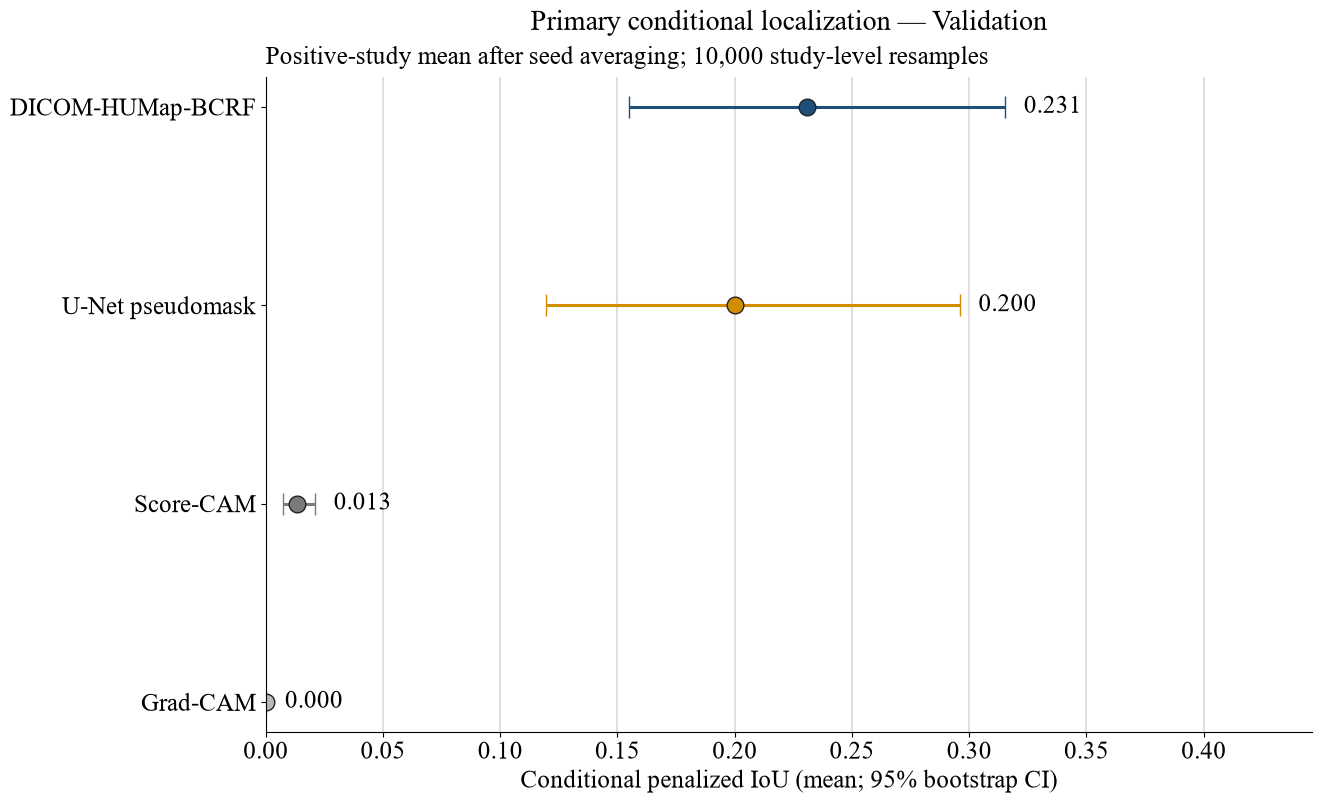

In [21]:
display_primary_table("validation")
plot_primary_split(
    "validation",
    "01_validation_primary_localization",
)

method,split,studies,mean,ci95_low,ci95_high
DICOM-HUMap-BCRF,locked_test,22,0.1714,0.1016,0.2506
U-Net pseudomask,locked_test,22,0.1700,0.0927,0.2576
Score-CAM,locked_test,22,0.0157,0.0075,0.0267
Grad-CAM,locked_test,22,0.0000,0.0000,0.0000


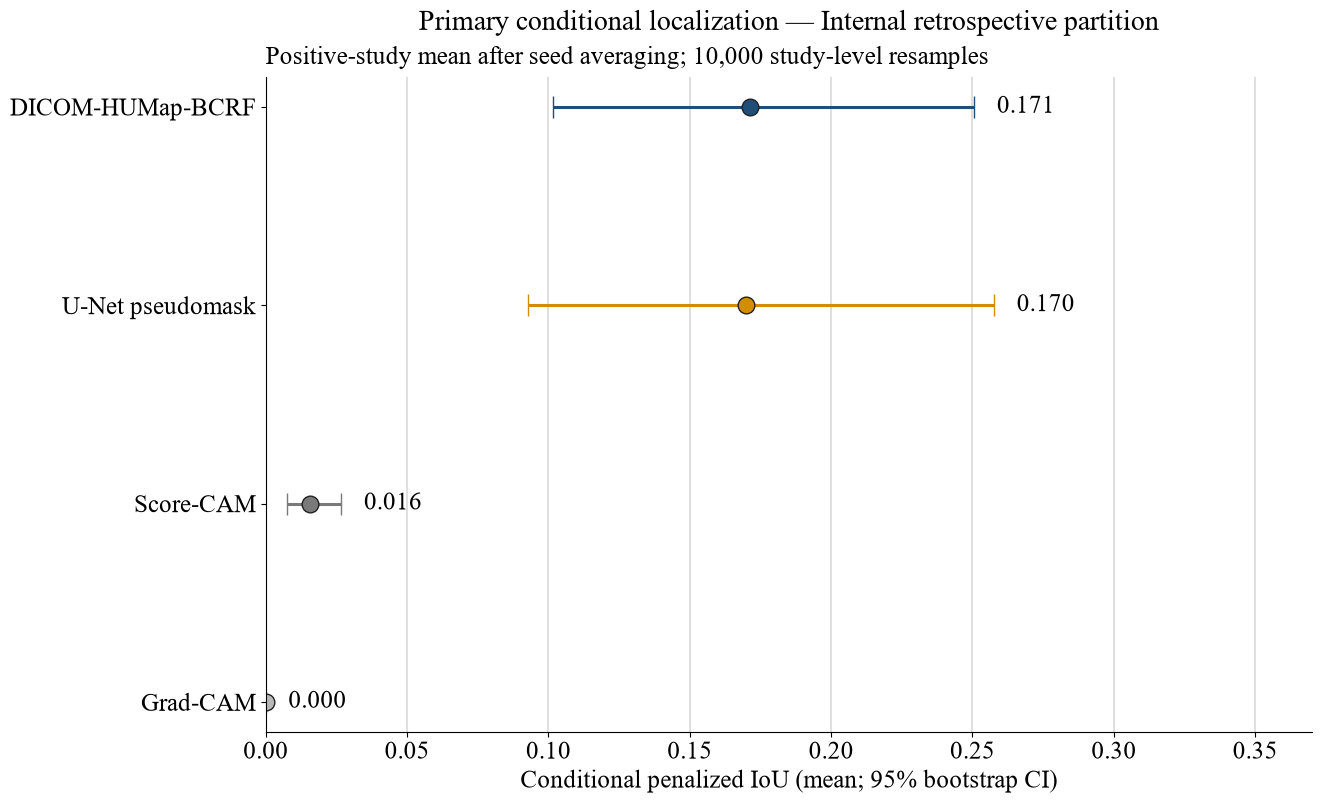

In [22]:
display_primary_table("locked_test")
plot_primary_split(
    "locked_test",
    "02_locked_test_primary_localization",
)

method,split,studies,mean,ci95_low,ci95_high
DICOM-HUMap-BCRF,cbis_ddsm_calc_test,151,0.0638,0.0506,0.0777
U-Net pseudomask,cbis_ddsm_calc_test,151,0.0591,0.0459,0.0736
Score-CAM,cbis_ddsm_calc_test,151,0.0086,0.0066,0.0108
Grad-CAM,cbis_ddsm_calc_test,151,0.0000,0.0000,0.0001


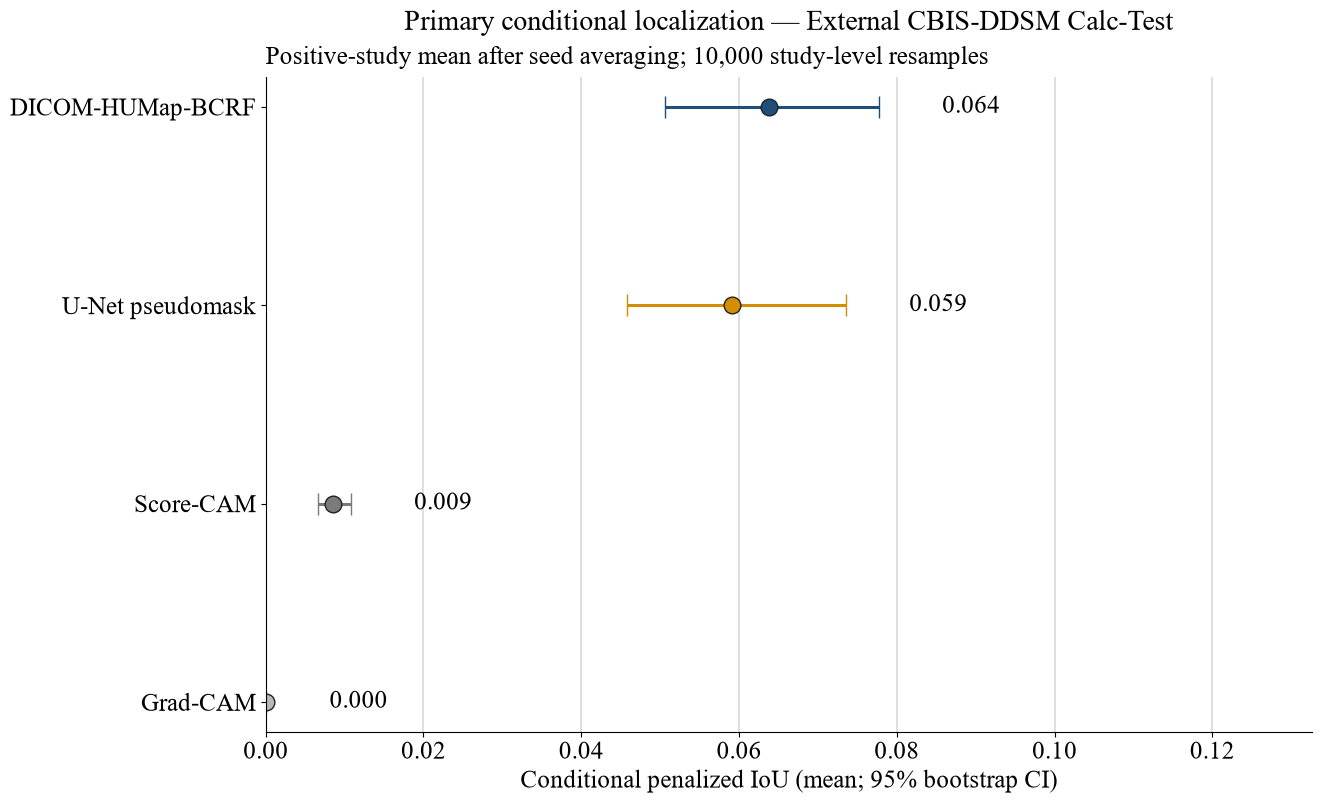

In [23]:
display_primary_table("cbis_ddsm_calc_test")
plot_primary_split(
    "cbis_ddsm_calc_test",
    "03_external_primary_localization",
)

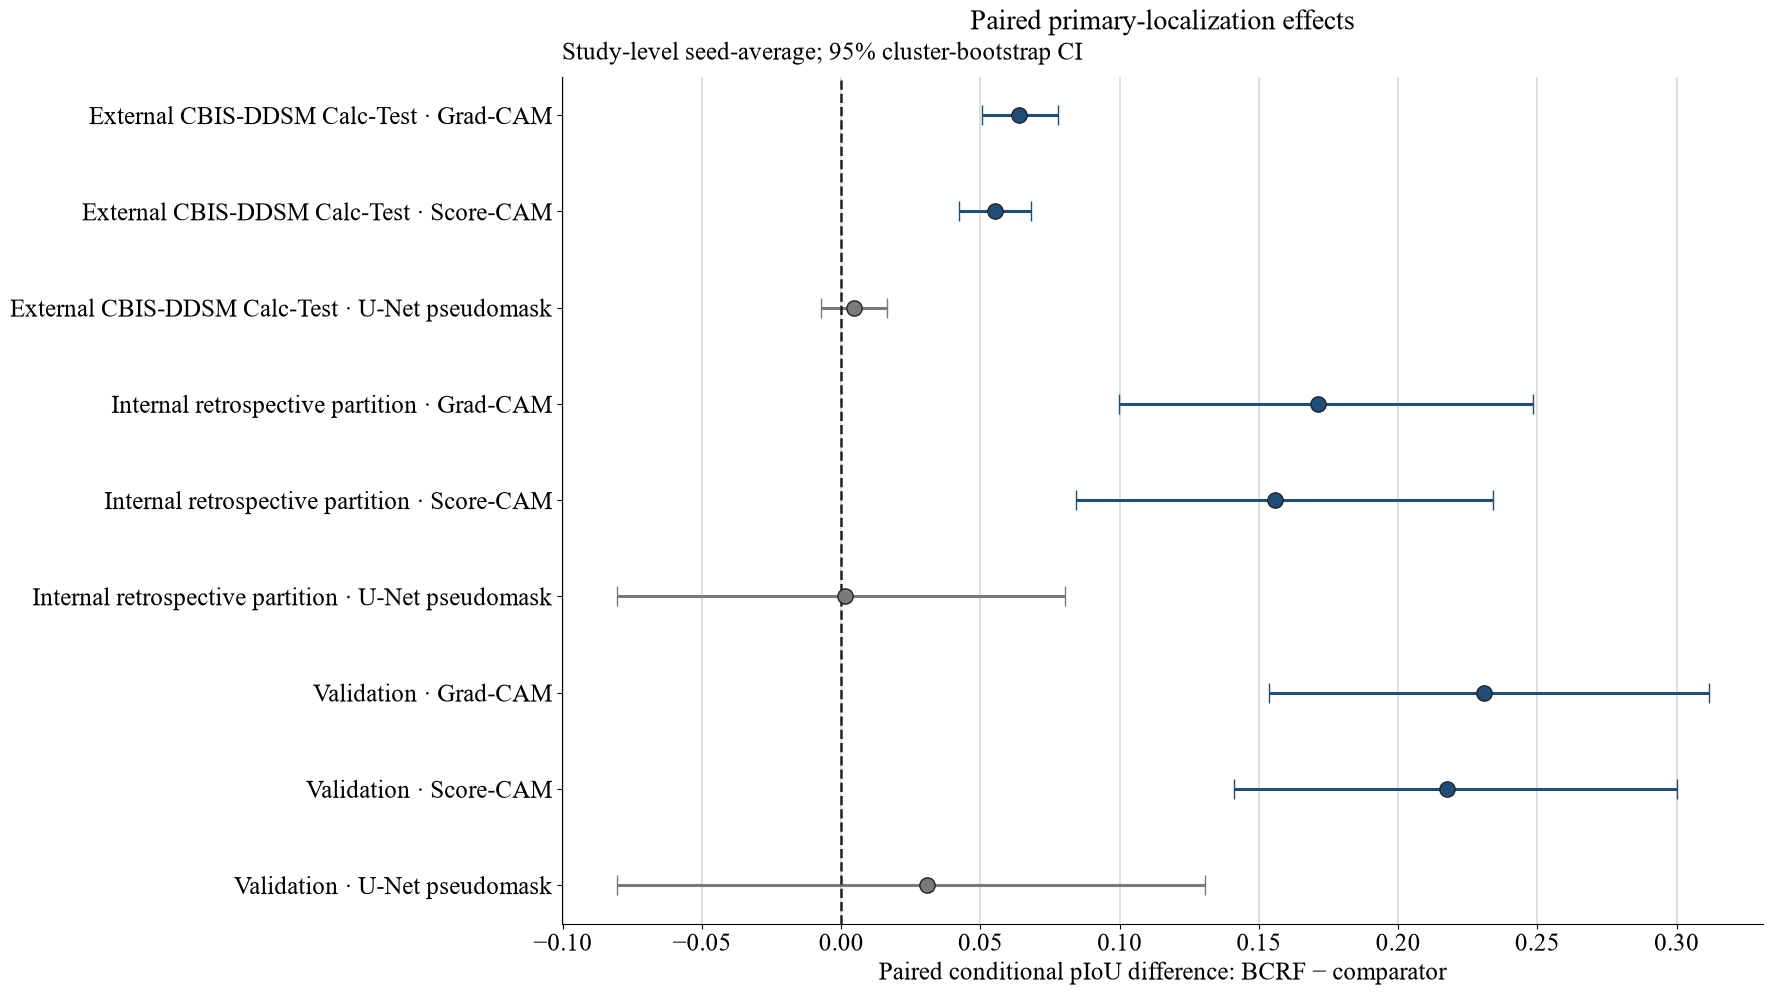

In [24]:
contrast_plot = model_contrasts.copy()
contrast_plot["label"] = (
    contrast_plot["split"].map(SPLIT_LABELS)
    + " · "
    + contrast_plot["comparator"]
)
contrast_plot = contrast_plot.sort_values(
    ["split", "mean_delta"],
    ascending=[True, False],
)
positions = np.arange(len(contrast_plot))[::-1]
significant = contrast_plot["ci95_low"].gt(0)
colors = np.where(significant, "#1F4E79", "#7A7A7A")

figure, axis = plt.subplots(figsize=(15.5, 11.0))
for position, row, color in zip(
    positions,
    contrast_plot.itertuples(),
    colors,
):
    axis.errorbar(
        row.mean_delta,
        position,
        xerr=np.array(
            [[row.mean_delta - row.ci95_low],
             [row.ci95_high - row.mean_delta]]
        ),
        fmt="o",
        markersize=11,
        capsize=7,
        linewidth=2.2,
        color=color,
        markeredgecolor="#222222",
    )
axis.axvline(0, color="#222222", linewidth=1.8, linestyle="--")
axis.set_yticks(positions, contrast_plot["label"])
axis.set_xlabel("Paired conditional pIoU difference: BCRF − comparator")
axis.set_title(
    "Paired primary-localization effects",
    fontsize=20,
    pad=34,
)
axis.text(
    0,
    1.02,
    "Study-level seed-average; 95% cluster-bootstrap CI",
    transform=axis.transAxes,
    fontsize=18,
)
axis.grid(axis="x", color="#D9D9D9", linewidth=1.2)
axis.spines[["top", "right"]].set_visible(False)
axis.tick_params(labelsize=18)
save_scientific_figure(
    figure,
    "04_paired_primary_localization_effects",
)

label,penalized_iou_mean,penalized_iou_sd,matched_iou_mean,peak_in_box_mean,box_recall_mean
No center-rank,0.2083,0.0369,0.2401,0.7121,0.5013
No morphology,0.2235,0.0239,0.2596,0.6591,0.6010
Equal loss balance,0.2237,0.0208,0.2610,0.6692,0.6174
Uniform fusion,0.2304,0.0227,0.2722,0.6970,0.5379
Full BCRF,0.2310,0.0263,0.2660,0.6768,0.5568


contrast,positive_studies,mean_delta,ci95_low,ci95_high,wilcoxon_p,holm_p,analysis_role
full_bcrf - no_morphology,22,0.0075,-0.0286,0.0453,0.4873,1.0000,exploratory development
full_bcrf - no_center_rank,22,0.0227,-0.0193,0.0672,0.2314,0.9256,exploratory development
full_bcrf - uniform_fusion,22,0.0006,-0.0398,0.0413,0.5380,1.0000,exploratory development
full_bcrf - equal_balance,22,0.0073,-0.0297,0.0429,0.4119,1.0000,exploratory development


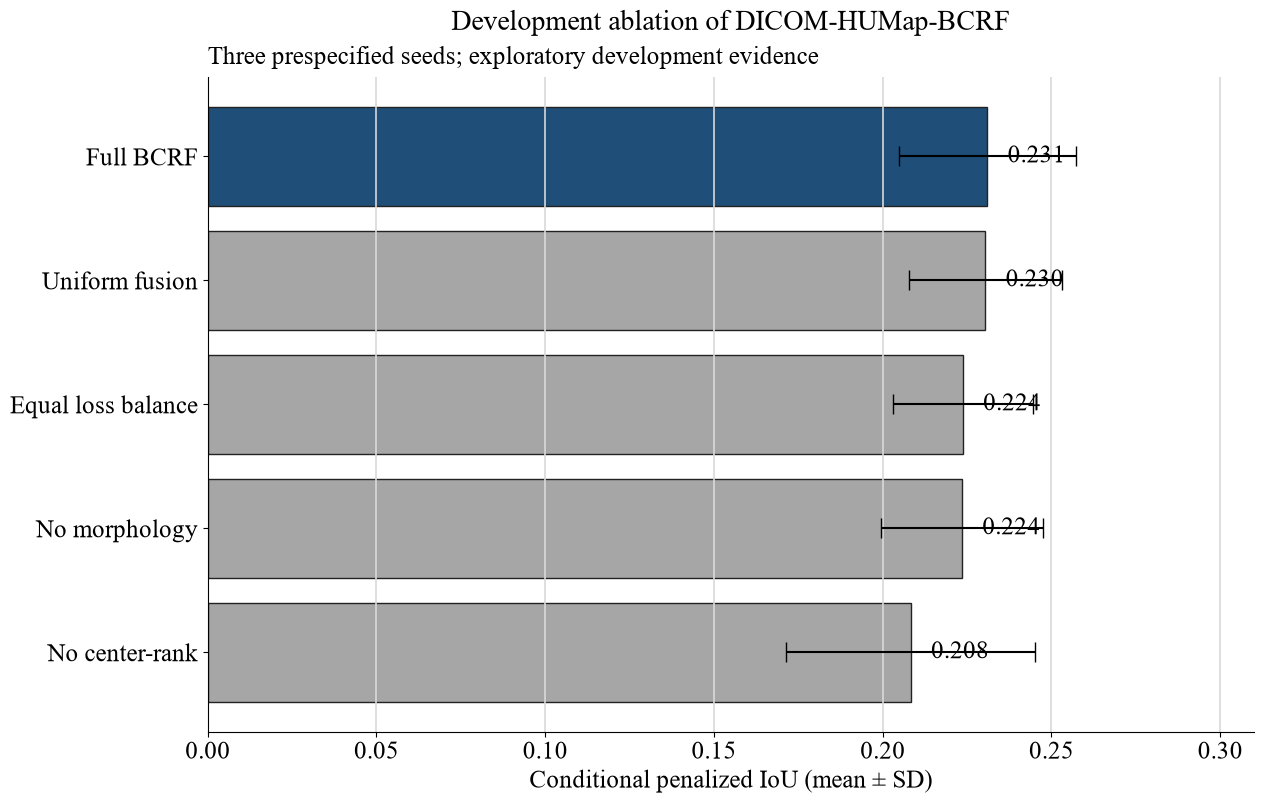

In [25]:
ablation_summary = pd.read_csv(
    TABLE_DIR / "bcrf_ablation_summary.csv"
)
ablation_contrasts = pd.read_csv(
    TABLE_DIR / "bcrf_paired_ablation_contrasts.csv"
)
variant_labels = {
    "full_bcrf": "Full BCRF",
    "uniform_fusion": "Uniform fusion",
    "equal_balance": "Equal loss balance",
    "no_morphology": "No morphology",
    "no_center_rank": "No center-rank",
}
ablation_plot = ablation_summary.assign(
    label=ablation_summary["variant"].map(variant_labels)
).sort_values("penalized_iou_mean", ascending=True)

display(
    ablation_plot[
        [
            "label",
            "penalized_iou_mean",
            "penalized_iou_sd",
            "matched_iou_mean",
            "peak_in_box_mean",
            "box_recall_mean",
        ]
    ]
    .style.hide(axis="index")
    .format(precision=4)
    .highlight_max(
        subset=["penalized_iou_mean"],
        props="font-weight: bold;",
    )
)
display(
    ablation_contrasts.style.hide(axis="index").format(
        {
            "mean_delta": "{:.4f}",
            "ci95_low": "{:.4f}",
            "ci95_high": "{:.4f}",
            "wilcoxon_p": "{:.4f}",
            "holm_p": "{:.4f}",
        }
    )
)

figure, axis = plt.subplots(figsize=(13.5, 8.5))
colors = [
    "#1F4E79" if variant == "full_bcrf" else "#A6A6A6"
    for variant in ablation_plot["variant"]
]
bars = axis.barh(
    ablation_plot["label"],
    ablation_plot["penalized_iou_mean"],
    xerr=ablation_plot["penalized_iou_sd"],
    color=colors,
    edgecolor="#222222",
    capsize=7,
)
for bar, value in zip(
    bars,
    ablation_plot["penalized_iou_mean"],
):
    axis.text(
        value + 0.006,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=18,
    )
axis.set_xlim(0, 0.31)
axis.set_xlabel("Conditional penalized IoU (mean ± SD)")
axis.set_title(
    "Development ablation of DICOM-HUMap-BCRF",
    fontsize=20,
    pad=34,
)
axis.text(
    0,
    1.02,
    "Three prespecified seeds; exploratory development evidence",
    transform=axis.transAxes,
    fontsize=18,
)
axis.grid(axis="x", color="#D9D9D9", linewidth=1.2)
axis.spines[["top", "right"]].set_visible(False)
axis.tick_params(labelsize=18)
save_scientific_figure(
    figure,
    "05_development_ablation_primary_localization",
)

## Secondary classification and residual-risk evidence

These endpoints are descriptive. The internal partition is retrospective, classification is image-level, and the learned residual-risk map is not treated as calibrated clinical uncertainty. Selective curves rank study-level pIoU after averaging seeds; the summary table reports image-level metrics per seed, so the two grains are intentionally distinct.

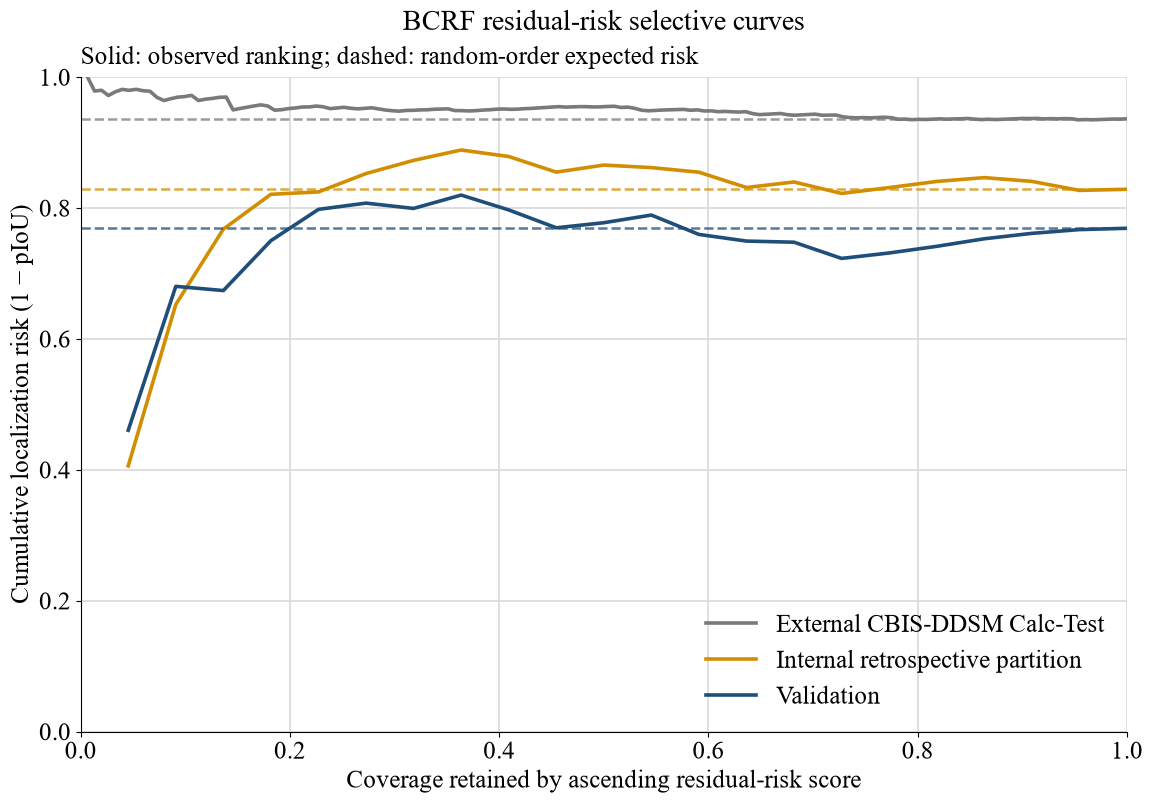

split,error_spearman_mean,error_spearman_sd,selective_aurc_mean,selective_aurc_sd,mean_residual_risk
cbis_ddsm_calc_test,-0.0507,0.0447,0.9493,0.0031,0.4051
locked_test,0.0266,0.2297,0.8157,0.0275,0.4230
validation,0.1016,0.1372,0.7613,0.0290,0.4204


In [26]:
bcrf_uncertainty = all_predictions[
    all_predictions["method"].eq("DICOM-HUMap-BCRF")
    & all_predictions["label"].eq(1)
    & all_predictions["mean_uncertainty"].notna()
].copy()
uncertainty_study = (
    bcrf_uncertainty.groupby(
        ["split", "seed", "study_id"],
        as_index=False,
    )
    .agg(
        penalized_iou=("penalized_iou", "mean"),
        mean_uncertainty=("mean_uncertainty", "mean"),
    )
    .groupby(["split", "study_id"], as_index=False)
    .mean(numeric_only=True)
)
risk_colors = {
    "validation": "#1F4E79",
    "locked_test": "#D28E00",
    "cbis_ddsm_calc_test": "#7A7A7A",
}

figure, axis = plt.subplots(figsize=(13.5, 8.5))
for split, frame in uncertainty_study.groupby("split", sort=True):
    ordered = frame.sort_values(
        "mean_uncertainty",
        ascending=True,
    )
    risk = 1.0 - ordered["penalized_iou"].to_numpy()
    coverage = np.arange(1, len(risk) + 1) / len(risk)
    selective_risk = np.cumsum(risk) / np.arange(
        1,
        len(risk) + 1,
    )
    color = risk_colors[split]
    axis.plot(
        coverage,
        selective_risk,
        color=color,
        linewidth=2.6,
        label=SPLIT_LABELS[split],
    )
    axis.axhline(
        risk.mean(),
        color=color,
        linewidth=1.8,
        linestyle="--",
        alpha=0.75,
    )
axis.set_xlim(0, 1)
axis.set_ylim(0, 1)
axis.set_xlabel("Coverage retained by ascending residual-risk score")
axis.set_ylabel("Cumulative localization risk (1 − pIoU)")
axis.set_title(
    "BCRF residual-risk selective curves",
    fontsize=20,
    pad=34,
)
axis.text(
    0,
    1.02,
    "Solid: observed ranking; dashed: random-order expected risk",
    transform=axis.transAxes,
    fontsize=18,
)
axis.legend(loc="lower right", fontsize=18, frameon=False)
axis.grid(color="#D9D9D9", linewidth=1.2)
axis.spines[["top", "right"]].set_visible(False)
axis.tick_params(labelsize=18)
save_scientific_figure(
    figure,
    "10_bcrf_selective_risk",
)
display(
    uncertainty_summary.style.hide(axis="index").format(precision=4)
)

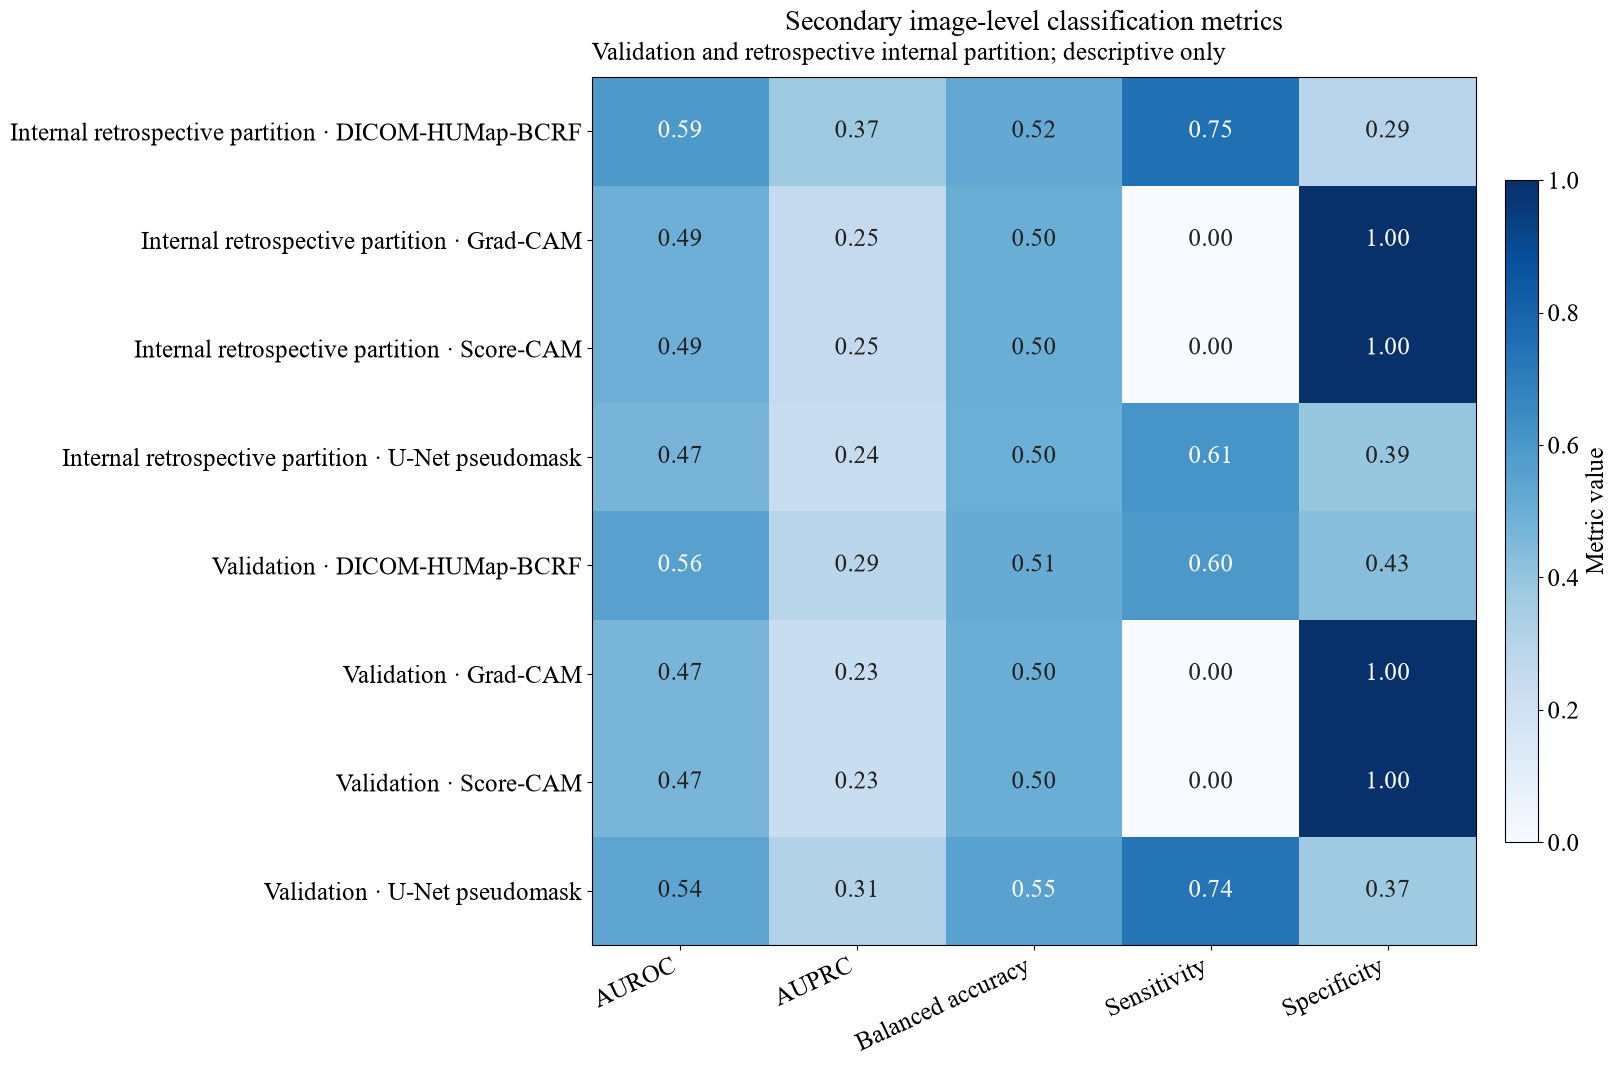

In [27]:
classification_metrics = [
    "auroc_mean",
    "auprc_mean",
    "balanced_accuracy_mean",
    "sensitivity_mean",
    "specificity_mean",
]
classification_labels = [
    "AUROC",
    "AUPRC",
    "Balanced accuracy",
    "Sensitivity",
    "Specificity",
]
classification_plot = classification_summary.copy()
classification_plot["row_label"] = (
    classification_plot["split"].map(SPLIT_LABELS)
    + " · "
    + classification_plot["method"]
)
classification_plot = classification_plot.sort_values(
    ["split", "method"],
    ascending=True,
)
matrix = classification_plot[classification_metrics].to_numpy()

figure, axis = plt.subplots(figsize=(16.5, 11.0))
image = axis.imshow(
    matrix,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto",
)
axis.set_xticks(
    np.arange(len(classification_labels)),
    classification_labels,
    rotation=25,
    ha="right",
)
axis.set_yticks(
    np.arange(len(classification_plot)),
    classification_plot["row_label"],
)
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = matrix[row_index, column_index]
        axis.text(
            column_index,
            row_index,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value >= 0.55 else "#222222",
            fontsize=18,
        )
colorbar = figure.colorbar(
    image,
    ax=axis,
    fraction=0.035,
    pad=0.03,
)
colorbar.set_label("Metric value", fontsize=18)
colorbar.ax.tick_params(labelsize=18)
axis.set_title(
    "Secondary image-level classification metrics",
    fontsize=20,
    pad=34,
)
axis.text(
    0,
    1.02,
    "Validation and retrospective internal partition; descriptive only",
    transform=axis.transAxes,
    fontsize=18,
)
axis.tick_params(labelsize=18)
figure.tight_layout()
save_scientific_figure(
    figure,
    "11_secondary_classification_metrics",
)

## Prespecified practical evidence

A single positive image from the internal retrospective partition is selected independently of model outputs: its total annotated bbox area is closest to the positive-cohort median. Every method uses the same image and seed 17; target boxes are solid and system predictions are dashed.

In [28]:
PRACTICAL_SEED = 17

def total_target_area(boxes_json: str) -> float:
    boxes = json.loads(boxes_json)
    return float(
        sum(
            max(0.0, x2 - x1) * max(0.0, y2 - y1)
            for x1, y1, x2, y2 in boxes
        )
    )

positive_locked = locked_frame[locked_frame["label"].eq(1)].copy()
positive_locked["target_area"] = positive_locked[
    "boxes_1024_json"
].map(total_target_area)
median_area = float(positive_locked["target_area"].median())
representative_index = (
    positive_locked["target_area"] - median_area
).abs().idxmin()
practical_frame = positive_locked.loc[[representative_index]].copy()

practical_batch = next(
    iter(frozen_loader(practical_frame, image_cache))
)
PRACTICAL_IMAGE = practical_batch["image"][
    0, 0
].cpu().numpy()
PRACTICAL_VALID = practical_batch["valid_mask"][
    0, 0
].cpu().numpy().astype(bool)
PRACTICAL_TARGETS = json.loads(
    practical_batch["boxes_json"][0]
)
PRACTICAL_IMAGE_ID = practical_batch["image_id"][0]

def practical_prediction_row(
    method: str,
) -> pd.Series:
    rows = locked_predictions[
        locked_predictions["method"].eq(method)
        & locked_predictions["seed"].eq(PRACTICAL_SEED)
        & locked_predictions["image_id"].eq(PRACTICAL_IMAGE_ID)
    ]
    if len(rows) != 1:
        raise ValueError(
            f"Expected one practical row for {method}, got {len(rows)}"
        )
    row = rows.iloc[0]
    expected = artifact_lineage_for_row(
        str(row["method"]),
        int(row["seed"]),
    )
    for column in [
        "artifact_sha256",
        "source_checkpoint_sha256",
        "model_spec_sha256",
    ]:
        if str(row[column]) != str(expected[column]):
            raise ValueError(
                f"Practical lineage mismatch: {column}"
            )
    return row

In [29]:
def assert_boxes_close(
    observed: list[list[float]],
    expected: list[list[float]],
    atol: float = IMAGE_SIZE * 1e-4,
) -> None:
    observed_array = np.asarray(observed, dtype=float)
    expected_array = np.asarray(expected, dtype=float)
    if observed_array.shape != expected_array.shape:
        raise ValueError("Prediction box shape mismatch")
    if observed_array.size and not np.allclose(
        observed_array,
        expected_array,
        atol=atol,
        rtol=0,
    ):
        raise ValueError("Prediction boxes differ from frozen row")

def baseline_practical_output(
    raw_method: str,
) -> dict:
    display_method = METHOD_LABELS[raw_method]
    model = load_baseline_model(
        raw_method,
        PRACTICAL_SEED,
    )
    image = practical_batch["image"].to(
        DEVICE,
        non_blocking=True,
    )
    heatmap, probability = baseline_heatmap(
        raw_method,
        model,
        image,
    )
    threshold_row = selected_thresholds[
        selected_thresholds["method"].eq(raw_method)
        & selected_thresholds["seed"].eq(PRACTICAL_SEED)
    ].iloc[0]
    conditional_boxes = boxes_from_heatmap(
        heatmap,
        float(threshold_row["heatmap_threshold"]),
    )
    system_boxes = (
        conditional_boxes
        if probability >= float(
            threshold_row["presence_threshold"]
        )
        else []
    )
    row = practical_prediction_row(display_method)
    if not np.isclose(
        probability,
        float(row["probability"]),
        atol=1e-6,
        rtol=0,
    ):
        raise ValueError("Practical probability differs from frozen row")
    assert_boxes_close(
        conditional_boxes,
        json.loads(row["conditional_boxes_json"]),
    )
    assert_boxes_close(
        system_boxes,
        json.loads(row["system_boxes_json"]),
    )
    result = {
        "method": display_method,
        "heatmap": heatmap,
        "probability": probability,
        "conditional_penalized_iou": float(
            row["penalized_iou"]
        ),
        "system_penalized_iou": float(
            row["system_penalized_iou"]
        ),
        "predicted_boxes": system_boxes,
    }
    del model
    torch.cuda.empty_cache()
    return result

In [30]:
@torch.no_grad()
def bcrf_practical_output() -> dict:
    model = load_bcrf(PRACTICAL_SEED)
    image = practical_batch["image"].to(
        DEVICE,
        non_blocking=True,
    )
    valid = practical_batch["valid_mask"].to(
        DEVICE,
        non_blocking=True,
    )
    output = model(image, valid)
    probability = float(
        torch.sigmoid(output["presence_logits"])[0]
    )
    conditional_boxes = decode_bcrf(output)
    row = practical_prediction_row("DICOM-HUMap-BCRF")
    system_boxes = (
        conditional_boxes
        if probability >= float(row["presence_threshold"])
        else []
    )
    if not np.isclose(
        probability,
        float(row["probability"]),
        atol=1e-6,
        rtol=0,
    ):
        raise ValueError("Practical probability differs from frozen row")
    assert_boxes_close(
        conditional_boxes,
        json.loads(row["conditional_boxes_json"]),
    )
    assert_boxes_close(
        system_boxes,
        json.loads(row["system_boxes_json"]),
    )
    heatmap = F.interpolate(
        output["heatmap"],
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear",
        align_corners=False,
    )[0, 0].float().cpu().numpy()
    uncertainty = F.interpolate(
        output["uncertainty"],
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear",
        align_corners=False,
    )[0, 0].float().cpu().numpy()
    result = {
        "method": "DICOM-HUMap-BCRF",
        "heatmap": heatmap,
        "uncertainty": uncertainty,
        "probability": probability,
        "conditional_penalized_iou": float(
            row["penalized_iou"]
        ),
        "system_penalized_iou": float(
            row["system_penalized_iou"]
        ),
        "predicted_boxes": system_boxes,
    }
    del model
    torch.cuda.empty_cache()
    return result

display(
    pd.DataFrame(
        {
            "selection_rule": [
                "bbox area nearest positive retrospective-partition median"
            ],
            "image_id": [PRACTICAL_IMAGE_ID],
            "target_boxes": [len(PRACTICAL_TARGETS)],
            "target_area": [
                float(
                    positive_locked.loc[
                        representative_index,
                        "target_area",
                    ]
                )
            ],
        }
    ).style.hide(axis="index").format(
        {"target_area": "{:.1f}"}
    )
)

selection_rule,image_id,target_boxes,target_area
bbox area nearest positive retrospective-partition median,493609b26e1341ce737a60b5b930a757,1,8598.9


In [31]:
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

TARGET_COLOR = "#00A6D6"
PREDICTION_COLOR = "#F28E2B"
BOX_HANDLES = [
    Line2D(
        [0],
        [0],
        color=TARGET_COLOR,
        linewidth=3,
        linestyle="-",
        label="Reference bbox",
    ),
    Line2D(
        [0],
        [0],
        color=PREDICTION_COLOR,
        linewidth=3,
        linestyle="--",
        label="System prediction",
    ),
]

def draw_boxes(
    axis: plt.Axes,
    boxes: list[list[float]],
    color: str,
    linestyle: str,
) -> None:
    for x1, y1, x2, y2 in boxes:
        axis.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=color,
                linewidth=3,
                linestyle=linestyle,
            )
        )

def show_input(
    axis: plt.Axes,
) -> None:
    axis.imshow(
        PRACTICAL_IMAGE,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    draw_boxes(
        axis,
        PRACTICAL_TARGETS,
        TARGET_COLOR,
        "-",
    )
    axis.set_title("Standard DICOM input + reference", fontsize=20)
    axis.axis("off")

def show_heatmap(
    axis: plt.Axes,
    result: dict,
) -> plt.AxesImage:
    axis.imshow(
        PRACTICAL_IMAGE,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    heatmap = np.where(
        PRACTICAL_VALID,
        result["heatmap"],
        np.nan,
    )
    image = axis.imshow(
        heatmap,
        cmap="inferno",
        vmin=0,
        vmax=1,
        alpha=0.52,
    )
    draw_boxes(
        axis,
        PRACTICAL_TARGETS,
        TARGET_COLOR,
        "-",
    )
    draw_boxes(
        axis,
        result["predicted_boxes"],
        PREDICTION_COLOR,
        "--",
    )
    axis.set_title("Heatmap + reference/prediction", fontsize=20)
    axis.legend(
        handles=BOX_HANDLES,
        loc="lower center",
        fontsize=18,
        framealpha=0.92,
    )
    axis.axis("off")
    return image

In [32]:
def plot_baseline_practical(
    result: dict,
    stem: str,
) -> None:
    figure, axes = plt.subplots(
        1,
        2,
        figsize=(16.5, 8.5),
    )
    show_input(axes[0])
    heatmap_image = show_heatmap(axes[1], result)
    colorbar = figure.colorbar(
        heatmap_image,
        ax=axes[1],
        fraction=0.046,
        pad=0.03,
    )
    colorbar.set_label("Normalized attribution", fontsize=18)
    colorbar.ax.tick_params(labelsize=18)
    figure.suptitle(
        f"{result['method']} on prespecified internal retrospective image",
        fontsize=20,
    )
    figure.text(
        0.5,
        0.035,
        (
            f"Seed {PRACTICAL_SEED}; conditional pIoU="
            f"{result['conditional_penalized_iou']:.3f}; "
            f"system pIoU={result['system_penalized_iou']:.3f}; "
            f"presence score={result['probability']:.3f}"
        ),
        ha="center",
        fontsize=18,
    )
    figure.tight_layout(rect=[0, 0.07, 1, 0.93])
    save_scientific_figure(figure, stem)

def plot_bcrf_practical(
    result: dict,
) -> None:
    figure, axes = plt.subplots(
        1,
        3,
        figsize=(22.0, 8.0),
    )
    show_input(axes[0])
    heatmap_image = show_heatmap(axes[1], result)
    uncertainty = np.where(
        PRACTICAL_VALID,
        result["uncertainty"],
        np.nan,
    )
    uncertainty_image = axes[2].imshow(
        uncertainty,
        cmap="magma",
        vmin=0,
        vmax=1,
    )
    axes[2].set_title("Learned residual-risk map", fontsize=20)
    axes[2].axis("off")
    heatmap_colorbar = figure.colorbar(
        heatmap_image,
        ax=axes[1],
        fraction=0.046,
        pad=0.03,
    )
    heatmap_colorbar.set_label("Suspicion score", fontsize=18)
    heatmap_colorbar.ax.tick_params(labelsize=18)
    uncertainty_colorbar = figure.colorbar(
        uncertainty_image,
        ax=axes[2],
        fraction=0.046,
        pad=0.03,
    )
    uncertainty_colorbar.set_label("Residual-risk score", fontsize=18)
    uncertainty_colorbar.ax.tick_params(labelsize=18)
    figure.suptitle(
        "DICOM-HUMap-BCRF on prespecified internal retrospective image",
        fontsize=20,
    )
    figure.text(
        0.5,
        0.035,
        (
            f"Seed {PRACTICAL_SEED}; conditional pIoU="
            f"{result['conditional_penalized_iou']:.3f}; "
            f"system pIoU={result['system_penalized_iou']:.3f}; "
            f"presence probability={result['probability']:.3f}"
        ),
        ha="center",
        fontsize=18,
    )
    figure.tight_layout(rect=[0, 0.07, 1, 0.93])
    save_scientific_figure(
        figure,
        "06_bcrf_practical_locked_test",
    )

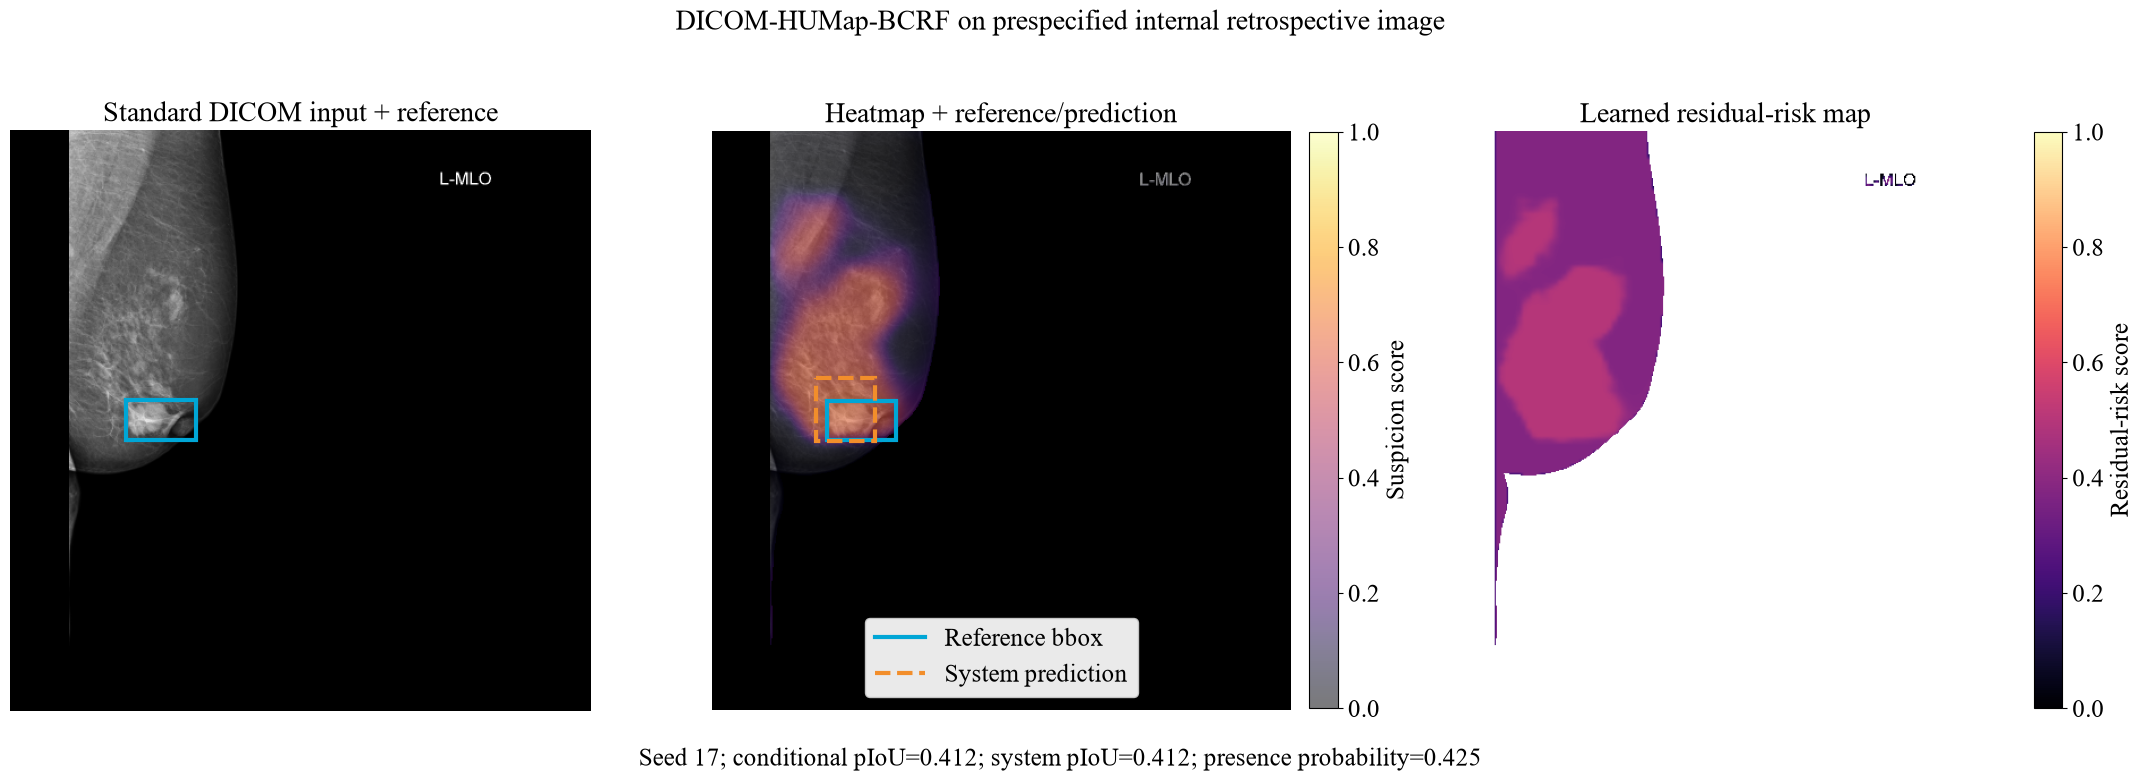

In [33]:
bcrf_practical = bcrf_practical_output()
plot_bcrf_practical(bcrf_practical)

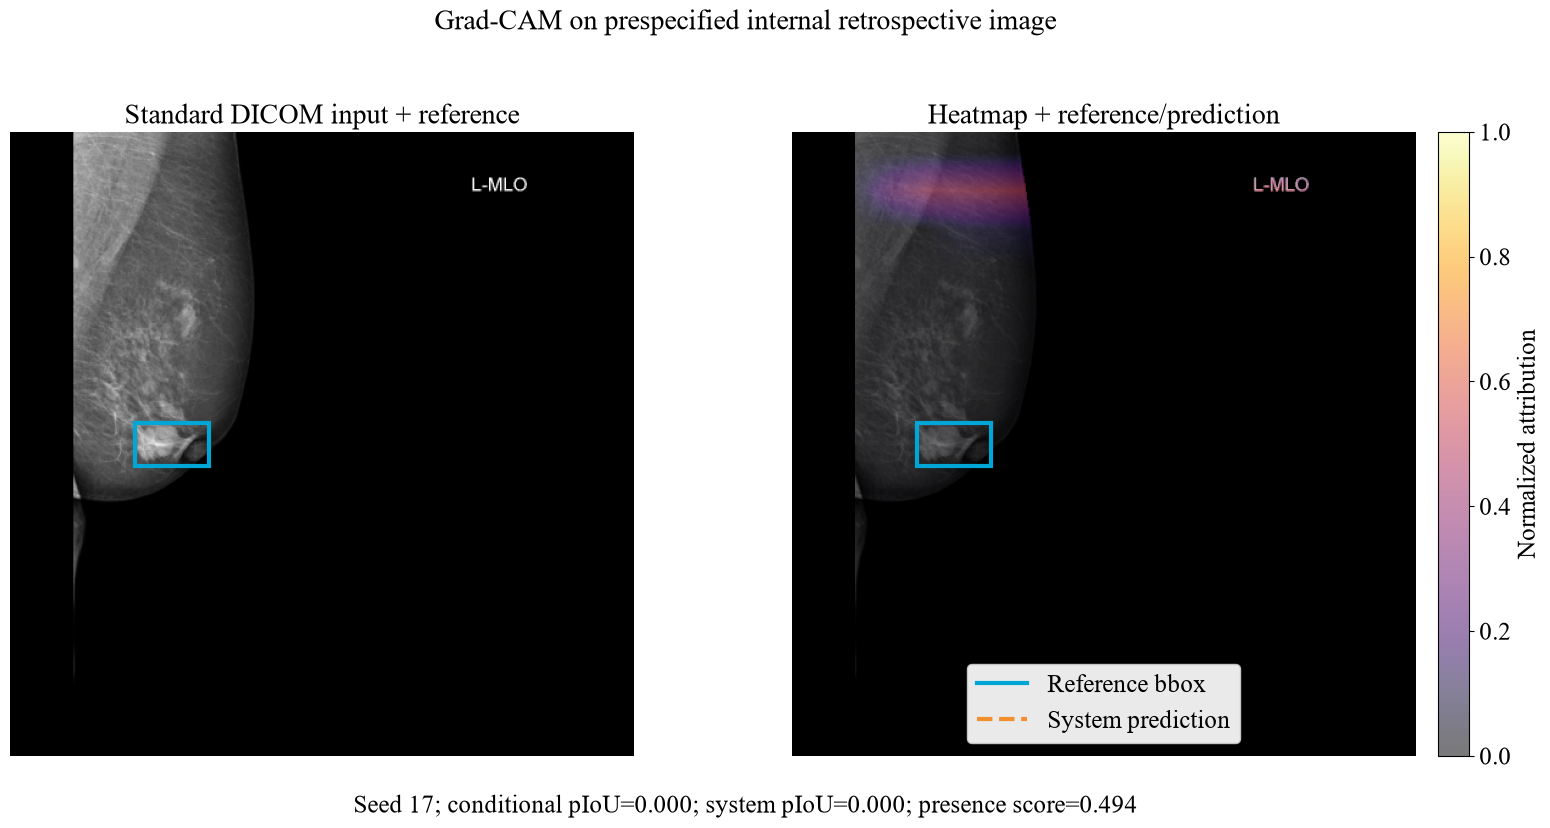

In [34]:
grad_cam_practical = baseline_practical_output("grad_cam")
plot_baseline_practical(
    grad_cam_practical,
    "07_grad_cam_practical_locked_test",
)

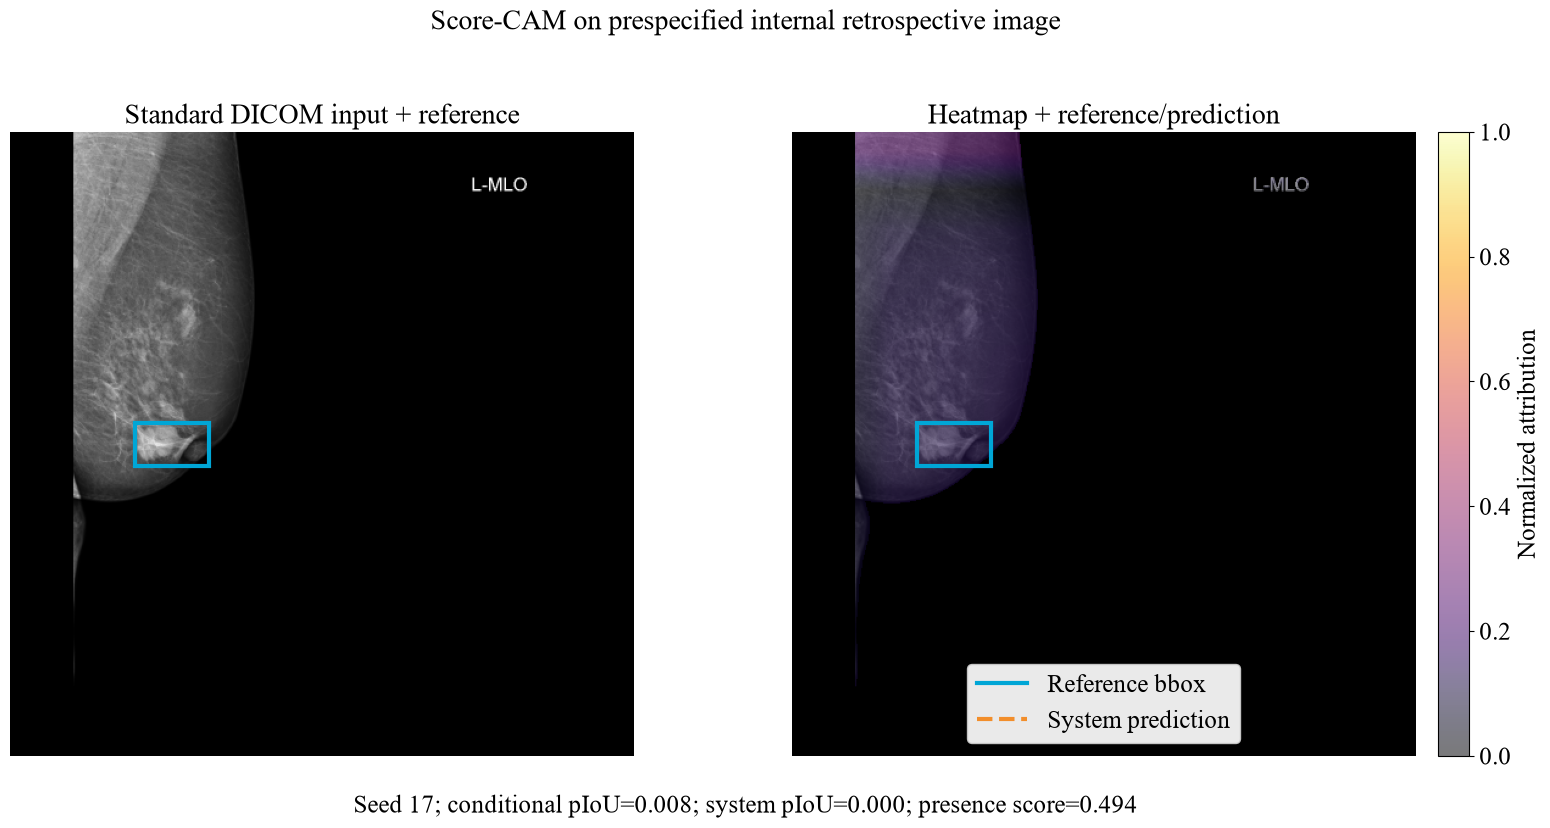

In [35]:
score_cam_practical = baseline_practical_output(
    "score_cam_top32"
)
plot_baseline_practical(
    score_cam_practical,
    "08_score_cam_practical_locked_test",
)

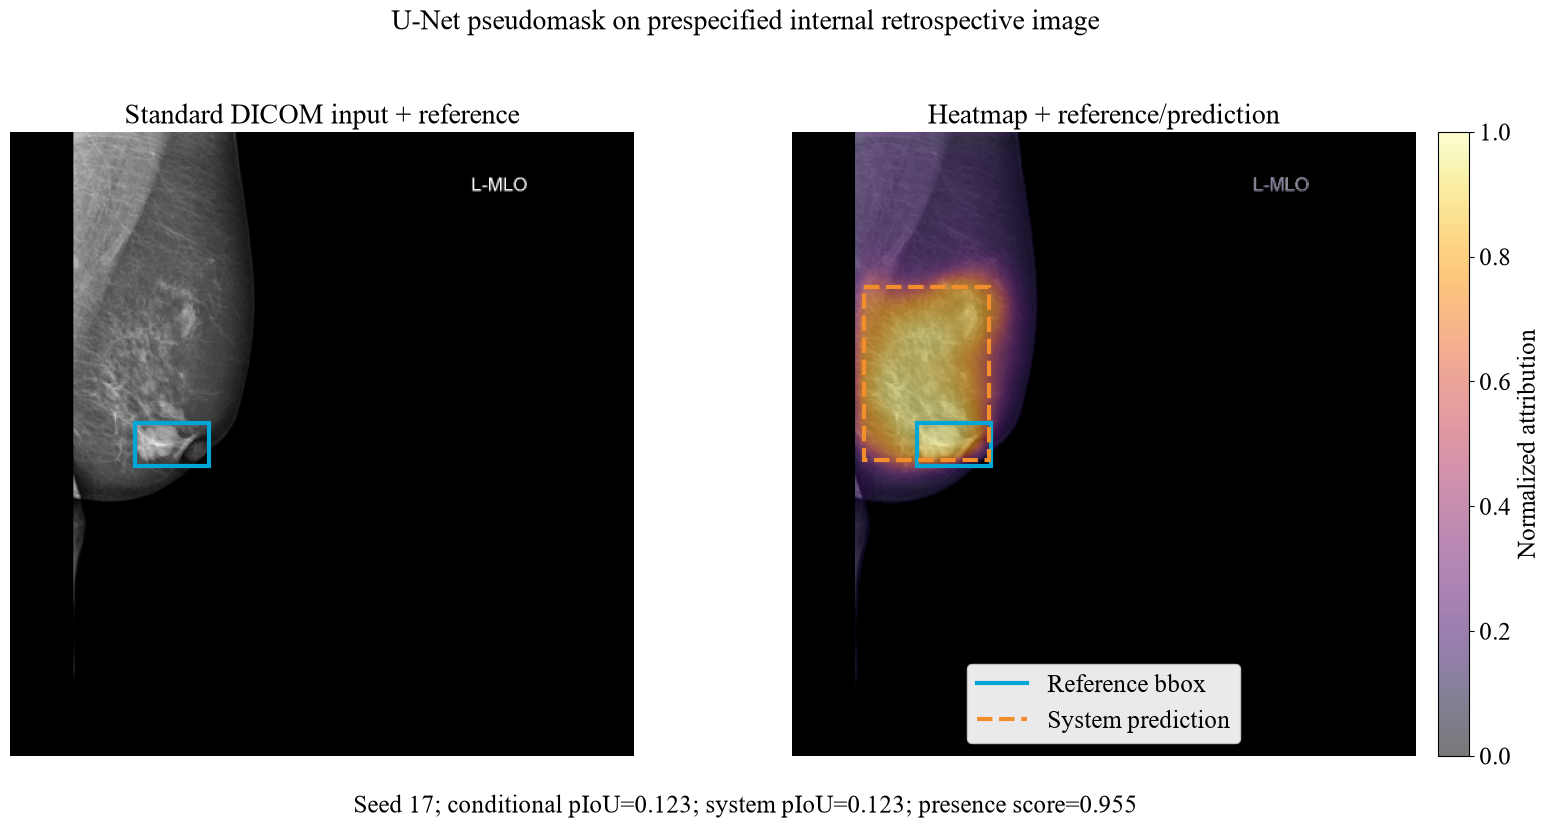

In [36]:
unet_practical = baseline_practical_output("unet_pseudomask")
plot_baseline_practical(
    unet_practical,
    "09_unet_practical_locked_test",
)

In [39]:
partition_frames = {
    "validation": records[records["split"].eq("validation")],
    "internal_retrospective": locked_frame,
    "external_cbis_ddsm": external_metadata,
}
box_capacity_rows = []
for partition, frame in partition_frames.items():
    box_counts = frame["boxes_1024_json"].map(
        lambda value: len(json.loads(value))
    )
    box_capacity_rows.append(
        {
            "partition": partition,
            "images": len(frame),
            "images_above_two_reference_boxes": int(box_counts.gt(2).sum()),
            "maximum_reference_boxes": int(box_counts.max()),
            "maximum_predicted_boxes": MAX_PREDICTED_BOXES,
        }
    )
box_capacity = pd.DataFrame(box_capacity_rows)
box_capacity.to_csv(
    TABLE_DIR / "bbox_capacity_by_partition.csv",
    index=False,
)


display(box_capacity.style.hide(axis="index"))


partition,images,images_above_two_reference_boxes,maximum_reference_boxes,maximum_predicted_boxes
validation,182,2,3,2
internal_retrospective,183,2,5,2
external_cbis_ddsm,284,3,5,2
